# Activity No. 1: Machine Learning Classification and Regression
### Instance: Food Inflation Prediction (Pune Tomato Wholesale Prices)

| | |
|---|---|
| **Batch** | A2 |
| **GitHub Repo** | [github.com/tusharkkp/AI-ML](https://github.com/tusharkkp/AI-ML/) |

| No. | Name | Roll No. | PRN |
|---|---|---|---|
| 1 | Tushar Kaldate | 47 | 202401040191 |
| 2 | Sakshi Shewale | 31 | 202401040126 |
| 3 | Samath Kadam | 33 | 202401040131 |

## 1. Aim

To build two machine learning models for the **Food Inflation Prediction** instance, one for **regression** and one for **classification**, each in two ways:

1. First with the ready-made **scikit-learn** version.
2. Then by writing **the same algorithm ourselves with only NumPy**, and checking that both versions give nearly the same answer.

* **Regression task:** predict the next wholesale modal price of tomato in the Pune APMC (Rs per quintal) with **Linear Regression**.
* **Classification task:** predict whether the price will **surge by more than 10% within the next 7 days** (an "inflation spike" alert) with **Logistic Regression**.

The activity is then extended into a full model comparison:

| Section | Content |
|---|---|
| **Foundation 1-2** | Linear Regression and Logistic Regression, scikit-learn vs NumPy |
| **Part A** | Classification with scikit-learn: SVM, Decision Tree, KNN, Gaussian Naive Bayes (+ cross-validation) |
| **Part B** | The same classifiers written from scratch in NumPy and compared with scikit-learn |
| **Part C** | Regression with scikit-learn: Linear, Ridge, Lasso, Decision Tree, KNN, Random Forest |
| **Part D** | Linear (Normal Equation), Ridge, KNN and Decision Tree regression from scratch |
| **Part E** | Gradient descent: batch, stochastic, mini-batch, learning rates, learning curves, convergence, scaling, `SGDRegressor` |
| **Part F** | Final analysis: best models, inflation indicators, limitations and improvements |

## 2. Experiment Objectives

1. Understand the difference between **regression** (predicting a number) and **classification** (predicting a class label) using a real food-price problem.
2. Prepare a time-series dataset properly: feature engineering, a **chronological** train/validation/test split, and feature scaling fitted on training data only (no data leakage).
3. Train **Linear Regression** and **Logistic Regression** using scikit-learn.
4. Re-implement both algorithms **from scratch with NumPy only** (normal equation for Linear Regression, batch gradient descent for Logistic Regression).
5. Evaluate with proper metrics (MAE, MSE, RMSE, R² for regression; Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrix and time-series cross-validation for classification), compare against simple baselines, and verify that the scikit-learn and NumPy results match.
6. Compare four more classifiers (SVM, Decision Tree, KNN, Gaussian Naive Bayes) and six regressors (Linear, Ridge, Lasso, Decision Tree, KNN, Random Forest), and re-implement KNN, Gaussian NB, Decision Tree, Linear SVM, Ridge and tree regression from scratch.
7. Study gradient descent in depth: batch, stochastic and mini-batch variants, learning-rate choice, learning curves, convergence and the effect of feature scaling.
8. Identify the best-performing algorithms and the most important inflation indicators, and state the limitations honestly.

## 3. Experiment Outcome

After completing this activity we will be able to:

* Frame one real-world problem (food inflation) as both a regression and a classification problem.
* Explain how Linear and Logistic Regression work internally (cost function, optimisation, decision rule).
* Implement both algorithms using only NumPy and demonstrate numerically that they match scikit-learn.
* Read evaluation metrics honestly, including noticing when a model barely beats a naive baseline or when the data distribution shifts between train and test periods.
* Explain how SVM, Decision Tree, KNN, Naive Bayes, Ridge, Lasso and Random Forest work, and show with NumPy that the hand-written versions agree with scikit-learn.
* Explain how learning rate, batch size and feature scaling decide whether gradient descent converges, wobbles or diverges.
* Judge models by validation and cross-validation (not by the test set) and recognise when a model that looks best in validation fails on a later period.

## 4. Conceptual Details

### 4.1 Regression vs Classification
| | Regression | Classification |
|---|---|---|
| Output | Continuous number | Discrete class label |
| Our task | Next modal price in Rs/quintal | Surge (1) or no surge (0) in the next 7 days |
| Algorithm used | Linear Regression | Logistic Regression |
| Main metrics | MAE, RMSE, R² | Accuracy, Precision, Recall, F1, ROC-AUC |

### 4.2 Linear Regression
Models the target as a weighted sum of the features:

$$\hat{y} = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n = X\theta$$

The parameters minimise the **Mean Squared Error**:

$$J(\theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

Setting the gradient to zero gives the closed-form **Normal Equation**, which is what scikit-learn solves (through a least-squares routine) and what we implement in NumPy:

$$\theta = (X^TX)^{-1}X^Ty$$

### 4.3 Logistic Regression
Passes the same linear score through the **sigmoid** function to obtain a probability:

$$p = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = X\theta$$

The prediction is class 1 if $p \ge 0.5$. There is no closed-form solution, so the parameters minimise the **log-loss** (binary cross-entropy) with **batch gradient descent**:

$$J(\theta) = -\frac{1}{m}\sum_{i}\left[y_i\log p_i + (1-y_i)\log(1-p_i)\right] + \frac{\lambda}{2m}\|\theta_{1:n}\|^2, \qquad \nabla J = \frac{1}{m}X^T(p-y) + \frac{\lambda}{m}\theta$$

* **L2 regularisation** ($\lambda = 1/C$ in scikit-learn) keeps the weights small and stabilises training.
* **Class weights ("balanced")**: surges are the minority class (about one third of days), so each sample is weighted by $\frac{m}{2\,m_{class}}$. Without this the model learns to say "no surge" every time and gets a decent accuracy while being useless as an alert.

### 4.4 Preprocessing and Evaluation Concepts
* **Feature scaling (standardisation):** $z=(x-\mu)/\sigma$ using *training-set* statistics only. It makes gradient descent converge and makes coefficients comparable.
* **Chronological split:** time-series data must be split by time (Train, then Validation, then Test). Random shuffling would let the model "see the future".
* **Naive persistence baseline:** "tomorrow's price = today's price". Any useful price model must beat this.
* **Regression metrics:** MAE (average absolute error, in Rs/quintal), RMSE (penalises large errors), R² (share of variance explained).
* **Classification metrics:** Precision (of the alerts raised, how many were real), Recall (of the real surges, how many were caught), F1 (harmonic mean of both), ROC-AUC (ranking quality, 0.5 = random).

### 4.5 Additional Classification Algorithms (Parts A and B)
| Algorithm | How it decides | Key hyper-parameter | Weakness |
|---|---|---|---|
| **SVM** | Finds the boundary with the widest margin: minimise $\tfrac12\|w\|^2 + C\sum_i \max(0,1-y_i f(x_i))$. The **RBF kernel** $K(x,x')=e^{-\gamma\|x-x'\|^2}$ gives a curved boundary; the **linear** kernel a straight one. | $C$ (penalty for margin violations) | Sensitive to scaling; no direct probabilities |
| **Decision Tree** | Repeatedly asks "is feature $j\le t$?", choosing the split with the largest drop in **Gini impurity** $G=2p(1-p)$ | `max_depth`, `min_samples_leaf` | Overfits easily; piecewise-constant |
| **KNN** | Class vote of the $k$ nearest training points (Euclidean distance) | $k$ | Needs scaling; slow for big data; no learning |
| **Gaussian Naive Bayes** | $P(c\mid x)\propto P(c)\prod_j \mathcal N(x_j\mid\mu_{cj},\sigma^2_{cj})$ assuming independent features | none | Independence assumption is wrong for correlated indicators |

**Evaluation tools:** the *confusion matrix* (TN, FP, FN, TP), *ROC-AUC* (probability that a random surge day gets a higher score than a random normal day), and **time-series cross-validation**: `TimeSeriesSplit` trains on the past and validates on the following block, so no future information leaks into training.

### 4.6 Additional Regression Algorithms (Parts C and D)
* **Ridge:** $\theta=(X^TX+\alpha P)^{-1}X^Ty$. The L2 penalty shrinks coefficients and stabilises correlated features.
* **Lasso:** adds $\alpha\|\theta\|_1$; it can set coefficients to exactly zero (feature selection). No closed form, solved by coordinate descent.
* **Decision Tree Regressor:** same splitting idea, but a split minimises the squared error and a leaf predicts the mean target.
* **KNN Regressor:** the mean target of the $k$ nearest points.
* **Random Forest:** the average of many trees, each trained on a bootstrap sample with random feature subsets; it reduces the variance of a single tree.

### 4.7 Gradient Descent (Part E)
Starting from $\theta=0$, repeat $\theta\leftarrow\theta-\alpha\nabla J(\theta)$.
* **Batch GD** uses all rows for each step (exact gradient, one update per epoch).
* **Stochastic GD** uses one random row per step (noisy, many updates, never settles exactly at a constant $\alpha$).
* **Mini-batch GD** uses a small batch (here 32), a compromise between the two.
* The **learning rate** $\alpha$ must be below $2/\lambda_{max}$ of the loss Hessian (for our MSE, $1/\lambda_{max}$ of $X^TX/m$ is the practical limit) or the iteration diverges; too small and it crawls.
* **Feature scaling** makes the loss surface rounder (better condition number), so one learning rate suits all directions.

## 5. Data Gathering (Where the Data Comes From)

This activity is the **next step of my research project, "AI-Based Food Inflation Prediction and Household Affordability Monitoring System"**. In the earlier step I inventoried and ranked public data sources (documented in `source_inventory.md`) and collected data from several of them:

| File | Source | What it holds |
|---|---|---|
| `cpi_data.csv` | MoSPI Consumer Price Index API | Monthly CPI index and YoY food inflation (All India / Maharashtra) |
| `wholesale_prices.csv` | data.gov.in Agmarknet Mandi Prices API | Daily wholesale min / max / modal mandi prices |
| `market_arrivals.csv` | Agmarknet mandi arrivals | Daily arrival quantities (tonnes) per market |
| `retail_prices.csv` | DCA Price Monitoring Bulletin (fcainfoweb) | All-India retail prices of 22 essential commodities |
| `household_expenditure.csv` | MoSPI NSSO HCES 2022-23 | Household food vs non-food spending shares |
| `model_ready_pune_tomato.csv` | Agmarknet historical archive (wholesale prices joined with arrivals) | **Cleaned, feature-engineered daily Pune tomato table used in this notebook** |

Sources that need a CAPTCHA or bot-challenge (AGMARKNET 2.0 reports, the DCA historical report form, RBI DBIE) were deliberately **not scraped**; only openly accessible APIs and archives were used. For this activity I use `model_ready_pune_tomato.csv`, because it is the only table that has a long, continuous daily price history together with arrivals, which is what supervised price prediction needs. The other files are the inputs for later steps of the project (CPI forecasting and household affordability).

## 6. Algorithm / Flowchart

### Overall pipeline
```
 +----------------------------+
 |  Load model_ready CSV      |
 +-------------+--------------+
               v
 +----------------------------+
 |  Data checks + fix faulty  |
 |  columns, build features   |
 +-------------+--------------+
               v
 +----------------------------+
 |  Chronological split       |
 |  Train / Validation / Test |
 +-------------+--------------+
               v
 +----------------------------+
 |  Standardise (train stats) |
 +------+---------------+-----+
        |               |
        v               v
 +-------------+   +-----------------+
 | REGRESSION  |   | CLASSIFICATION  |
 | next price  |   | 7-day surge Y/N |
 +------+------+   +--------+--------+
        v                   v
 +-------------+   +-----------------+
 | sklearn     |   | sklearn         |
 | LinearReg   |   | LogisticReg     |
 +------+------+   +--------+--------+
        v                   v
 +-------------+   +-----------------+
 | NumPy normal|   | NumPy gradient  |
 | equation    |   | descent         |
 +------+------+   +--------+--------+
        |                   |
        +---------+---------+
                  v
 +--------------------------------+
 | Compare coefficients,          |
 | predictions and metrics        |
 | (sklearn vs NumPy) + baselines |
 +--------------------------------+
```

### Algorithm A: Linear Regression (NumPy, normal equation)
1. Add a column of ones to X (intercept).
2. Compute $\theta = (X^TX)^{+}X^Ty$ (pseudo-inverse for numerical safety, since the price features are strongly correlated).
3. Predict $\hat{y} = X\theta$.

### Algorithm B: Logistic Regression (NumPy, batch gradient descent)
1. Add a column of ones to X; initialise $\theta = 0$.
2. Compute class weights so that both classes contribute equally.
3. Repeat for a fixed number of iterations:
   * $p = \sigma(X\theta)$
   * weighted gradient $g = \frac{1}{\sum w}\left[X^T\big(w\odot(p-y)\big)\right] + \frac{\lambda}{\sum w}\theta$ (no penalty on the intercept)
   * update $\theta \leftarrow \theta - \alpha g$
   * record the loss to check convergence
4. Predict class 1 when $\sigma(X\theta)\ge 0.5$.

### Algorithms for Parts A-F
```
 Parts A-D (classification and regression)         Part E (gradient descent)
 ------------------------------------------        --------------------------------------
 tune 1 hyper-parameter on VALIDATION set          theta <- 0
        |                                          repeat for each epoch:
 refit on TRAIN, score VALIDATION/TEST                 batch : theta -= lr * grad(all rows)
        |                                              SGD   : for each row (shuffled):
 cross-validate (TimeSeriesSplit)                                theta -= lr * grad(1 row)
        |                                              mini  : for each batch of 32 rows:
 NumPy re-implementation, same hyper-parameters                  theta -= lr * grad(batch)
        |                                              record train / validation MSE
 compare labels, scores, metrics with sklearn     compare with closed form + SGDRegressor
        |                                                  |
        +------------------------> Part F <---------------+
                 rank models, find indicators, limitations
```

**KNN (from scratch):** (1) compute the Euclidean distance from every query row to every training row; (2) take the $k$ smallest; (3) classification: vote (share of class 1 > 0.5), regression: mean target.

**Gaussian NB (from scratch):** (1) per class, store the prior, the mean and the variance of each feature; (2) for a new row compute $\log P(c)+\sum_j\log\mathcal N(x_j\mid\mu_{cj},\sigma_{cj}^2)$; (3) normalise with log-sum-exp and pick the larger class.

**Decision tree (from scratch):** (1) for each feature sort the values and try the midpoint between neighbouring values as the threshold; (2) compute the impurity decrease of every threshold with cumulative sums (weighted Gini for classification, squared error for regression); (3) take the best split, recurse on both sides until `max_depth`, `min_samples_leaf` or purity stops it; (4) a leaf returns the weighted class-1 share or the mean target.

**Linear SVM (from scratch):** (1) $y\in\{-1,+1\}$, class weights as before; (2) at each iteration find the points with margin $<1$; (3) sub-gradient $g_w=\lambda w-\frac{1}{\sum s}\sum_{viol}s_iy_ix_i$; (4) step $\frac{\alpha_0}{1+\alpha_0\lambda t}$; (5) average the second half of the iterates; (6) class 1 if $w\cdot x+b>0$.

**Ridge (from scratch):** $\theta=(X^TX+\alpha P)^{-1}X^Ty$ with $P=\text{diag}(0,1,\dots,1)$, solved with `np.linalg.solve`.

## 7. Python Code

### 7.1 Imports and settings

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn is used ONLY for the "ready-made" version and for cross-checking.
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 7.2 Locate and load the data files

In [2]:
def find_file(name):
    """Look for a data file in a few common folders (repo folder, ./data, upload folder)."""
    for folder in [".", "data", "../data", "/mnt/user-data/uploads"]:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"{name} not found. Put the CSV files next to this notebook or in ./data")

# Quick overview of every file gathered in the data-gathering step.
files = ["cpi_data.csv", "wholesale_prices.csv", "market_arrivals.csv",
         "retail_prices.csv", "household_expenditure.csv", "model_ready_pune_tomato.csv"]

overview = []
for f in files:
    df_tmp = pd.read_csv(find_file(f))
    if "observation_date" in df_tmp.columns:
        dates = pd.to_datetime(df_tmp["observation_date"])
        span = f"{dates.min().date()} to {dates.max().date()}"
    else:
        span = "survey data: " + ", ".join(df_tmp["survey_year"].astype(str).unique())
    overview.append({"file": f, "rows": len(df_tmp), "columns": df_tmp.shape[1], "coverage": span})
pd.DataFrame(overview)

,file,rows,columns,coverage
0,cpi_data.csv,12022,13,2014-01-01 to 2025-12-01
1,wholesale_prices.csv,71307,14,2016-01-01 to 2026-11-17
2,market_arrivals.csv,66745,10,2016-01-01 to 2018-12-31
3,retail_prices.csv,39187,12,2010-01-01 to 2026-11-17
4,household_expenditure.csv,152,9,survey data: 2022-23
5,model_ready_pune_tomato.csv,873,34,2016-01-08 to 2018-12-30


In [3]:
# The modelling table for this activity: daily Pune tomato wholesale prices + arrivals.
df = pd.read_csv(find_file("model_ready_pune_tomato.csv"), parse_dates=["observation_date"])
df = df.sort_values("observation_date").reset_index(drop=True)   # chronological order is essential
print("Shape:", df.shape)
print("Date range:", df["observation_date"].min().date(), "->", df["observation_date"].max().date())
print("Markets:", df["market_name"].unique(), "| Commodity:", df["commodity_name"].unique())
df[["observation_date", "modal_price_rs_per_qtl", "arrival_quantity_tonnes",
    "price_lag_7", "rolling_mean_7", "target_price_t_plus_1", "target_price_t_plus_7", "split_tag"]].head()

Shape: (873, 34)
Date range: 2016-01-08 -> 2018-12-30
Markets: <StringArray>
['Pune']
Length: 1, dtype: str | Commodity: <StringArray>
['Tomato']
Length: 1, dtype: str


,observation_date,modal_price_rs_per_qtl,arrival_quantity_tonnes,price_lag_7,rolling_mean_7,target_price_t_plus_1,target_price_t_plus_7,split_tag
0,2016-01-08,1500.0,214.0,2100.0,2128.571429,1600.0,1300.0,Train
1,2016-01-10,1600.0,147.0,2700.0,2057.142857,2200.0,1200.0,Train
2,2016-01-11,2200.0,284.0,2700.0,1985.714286,1300.0,1000.0,Train
3,2016-01-12,1300.0,133.0,2100.0,1785.714286,1300.0,1000.0,Train
4,2016-01-13,1300.0,189.0,2000.0,1671.428571,1200.0,900.0,Train


### 7.3 Data quality checks

In [4]:
# Check 1: is price_lag_1 really a lag? (it should equal the PREVIOUS day's price)
same_as_today = (df["price_lag_1"] == df["modal_price_rs_per_qtl"]).mean()
same_as_prev  = (df["price_lag_1"] == df["modal_price_rs_per_qtl"].shift(1)).mean()
print(f"price_lag_1 == today's modal price : {same_as_today:.1%}")
print(f"price_lag_1 == previous observation: {same_as_prev:.1%}")

# Check 2: duplicate columns
print("arrival_tonnes duplicates arrival_quantity_tonnes:",
      bool((df["arrival_tonnes"] == df["arrival_quantity_tonnes"]).all()))

# Check 3: is the t+1 target simply the next observation's price?
align = (df["target_price_t_plus_1"] == df["modal_price_rs_per_qtl"].shift(-1)).mean()
print(f"target_price_t_plus_1 == next observation's price: {align:.1%}")

# Check 4: spacing of observations and missing values
gap = df["observation_date"].diff().dt.days
print("\nDays between observations -> mean %.2f, max %d" % (gap.mean(), gap.max()))
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nRows per split:\n", df["split_tag"].value_counts())

price_lag_1 == today's modal price : 100.0%
price_lag_1 == previous observation: 43.5%
arrival_tonnes duplicates arrival_quantity_tonnes: True
target_price_t_plus_1 == next observation's price: 99.9%

Days between observations -> mean 1.25, max 6
Missing values:
 target_price_t_plus_7    6
dtype: int64

Rows per split:
 split_tag
Train         611
Test          132
Validation    130
Name: count, dtype: int64


**Findings from the checks.**
* `price_lag_1` is identical to today's price in 100% of rows, so it is **not a real lag** (a pipeline bug in the earlier step). Using it would just duplicate the `modal_price_rs_per_qtl` column and cause perfect collinearity. I replace it with a correct feature, `price_prev_obs` (the previous observation's price).
* `arrival_tonnes` is an exact duplicate of `arrival_quantity_tonnes`, so it is dropped.
* The market does not report every calendar day (average gap about 1.25 days), so "t+1" means *the next reported observation*. This is also how the provided target column was built, so I keep it.
* 6 rows have no 7-day-ahead target and are dropped for the classification task.

### 7.4 Feature engineering and targets

In [5]:
# Correct lag feature (replaces the faulty price_lag_1). shift(1) only looks at the PAST, so no leakage.
df["price_prev_obs"] = df["modal_price_rs_per_qtl"].shift(1)

# ---- Scale-free (ratio) features for CLASSIFICATION -------------------------------------------
# Tomato prices were very high in 2016-17 and much lower in 2018 (a level shift). A classifier
# built on raw Rs values would learn "high price level => ..." and fail on the test period.
# Ratios and percentage changes describe the *behaviour* of the price, not its level.
df["dev_mean7"]  = df["modal_price_rs_per_qtl"] / df["rolling_mean_7"] - 1            # price vs 7-day average
df["cv7"]        = df["rolling_std_7"] / df["rolling_mean_7"]                         # volatility (coef. of variation)
df["mom7_pct"]   = df["price_momentum_7"] / df["price_lag_7"]                         # 7-day % momentum
df["chg1_pct"]   = df["modal_price_rs_per_qtl"] / df["price_prev_obs"] - 1            # 1-step % change
df["spread_pct"] = df["daily_spread"] / df["modal_price_rs_per_qtl"]                  # (max-min)/modal
df["range7_pct"] = (df["rolling_max_7"] - df["rolling_min_7"]) / df["rolling_mean_7"] # 7-day price range
df["arr_dev"]    = df["arrival_quantity_tonnes"] / df["rolling_arrival_mean_7"] - 1   # arrivals vs 7-day average
df["arr_chg"]    = df["arrival_quantity_tonnes"] / df["arrival_lag_1"] - 1            # change in arrivals

# Feature lists
REG_FEATURES = ["modal_price_rs_per_qtl", "price_prev_obs", "price_lag_3", "price_lag_7",
                "rolling_mean_7", "rolling_std_7", "rolling_min_7", "rolling_max_7",
                "price_momentum_7", "daily_spread", "arrival_quantity_tonnes",
                "arrival_lag_1", "rolling_arrival_mean_7", "month", "day_of_week",
                "is_monsoon_season"]
CLF_FEATURES = ["dev_mean7", "cv7", "mom7_pct", "chg1_pct", "spread_pct", "range7_pct",
                "arr_dev", "arr_chg", "is_monsoon_season", "month"]

# Targets
REG_TARGET = "target_price_t_plus_1"                       # next modal price (Rs/quintal)
# Classification target: 1 if the price 7 days ahead is more than 10% above today's price
df["surge_7d"] = (df["target_price_t_plus_7"] > 1.10 * df["modal_price_rs_per_qtl"]).astype(int)

# Drop rows that cannot be used (first row has no previous price; last rows have no t+7 target)
df = df.dropna(subset=["price_prev_obs", "target_price_t_plus_1", "target_price_t_plus_7"]).reset_index(drop=True)
print("Rows after cleaning:", len(df))
print("Surge rate (share of days followed by a >10% rise within 7 days):", round(df["surge_7d"].mean(), 3))

Rows after cleaning: 866
Surge rate (share of days followed by a >10% rise within 7 days): 0.336


### 7.5 Chronological train / validation / test split

In [6]:
# The 'split_tag' column already holds a time-ordered split (Train < Validation < Test).
train = df[df["split_tag"] == "Train"]
val   = df[df["split_tag"] == "Validation"]
test  = df[df["split_tag"] == "Test"]

summary = pd.DataFrame({
    "rows":        [len(train), len(val), len(test)],
    "from":        [s["observation_date"].min().date() for s in (train, val, test)],
    "to":          [s["observation_date"].max().date() for s in (train, val, test)],
    "mean price":  [round(s["modal_price_rs_per_qtl"].mean(), 1) for s in (train, val, test)],
    "surge rate":  [round(s["surge_7d"].mean(), 3) for s in (train, val, test)],
}, index=["Train", "Validation", "Test"])
summary

,rows,from,to,mean price,surge rate
Train,610,2016-01-10,2018-02-18,1392.3,0.341
Validation,130,2018-02-19,2018-07-23,655.4,0.323
Test,126,2018-07-24,2018-12-23,684.1,0.325


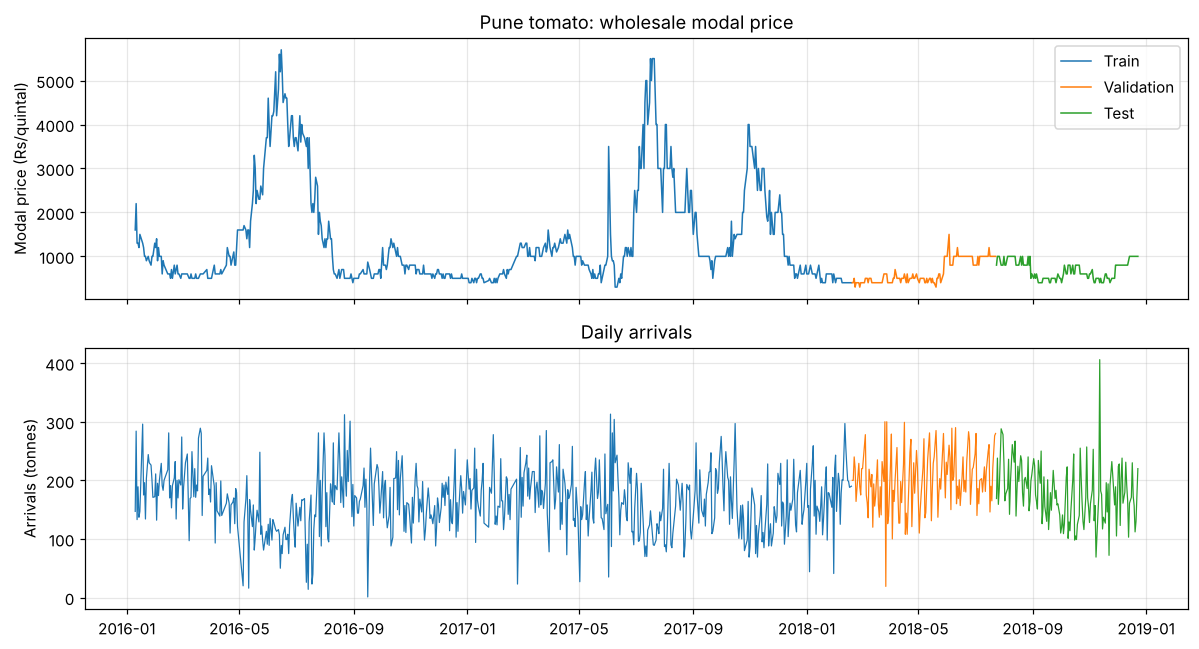

In [7]:
# Visual check of the series and the split boundaries
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for name, part, colour in [("Train", train, "tab:blue"), ("Validation", val, "tab:orange"), ("Test", test, "tab:green")]:
    ax[0].plot(part["observation_date"], part["modal_price_rs_per_qtl"], color=colour, label=name, lw=1)
    ax[1].plot(part["observation_date"], part["arrival_quantity_tonnes"], color=colour, lw=0.8)
ax[0].set_ylabel("Modal price (Rs/quintal)"); ax[0].set_title("Pune tomato: wholesale modal price")
ax[0].legend(); ax[1].set_ylabel("Arrivals (tonnes)"); ax[1].set_title("Daily arrivals")
plt.tight_layout(); plt.show()

The price level is clearly **not stationary**: it is much higher and more volatile in 2016-17 (training) than in 2018 (validation and test). That is the reason the classification features are ratios, and it is something to keep in mind when reading the results.

### 7.6 Helper functions written from scratch (NumPy only)

In [8]:
# ---------------------------- Feature scaling ------------------------------------------------
def np_fit_scaler(X):
    """Learn mean and standard deviation from TRAINING data only."""
    return X.mean(axis=0), X.std(axis=0)          # ddof=0, same convention as scikit-learn

def np_transform(X, mu, sd):
    """Standardise: z = (x - mean) / std."""
    return (X - mu) / sd

def add_bias(X):
    """Prepend a column of ones so that theta[0] acts as the intercept."""
    return np.c_[np.ones(len(X)), X]

# ---------------------------- Regression metrics --------------------------------------------
def np_mae(y, p):  return np.mean(np.abs(y - p))
def np_rmse(y, p): return np.sqrt(np.mean((y - p) ** 2))
def np_r2(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

# ---------------------------- Classification metrics ----------------------------------------
def np_confusion(y, yhat):
    """Return [[TN, FP], [FN, TP]]."""
    tn = np.sum((y == 0) & (yhat == 0)); fp = np.sum((y == 0) & (yhat == 1))
    fn = np.sum((y == 1) & (yhat == 0)); tp = np.sum((y == 1) & (yhat == 1))
    return np.array([[tn, fp], [fn, tp]])

def np_clf_metrics(y, yhat):
    (tn, fp), (fn, tp) = np_confusion(y, yhat)
    acc  = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return acc, prec, rec, f1

def np_roc_auc(y, score):
    """ROC-AUC via the rank (Mann-Whitney U) formula; ties get the average rank."""
    order = np.argsort(score)
    sorted_scores = score[order]
    ranks = np.empty(len(score))
    i = 0
    while i < len(score):                          # assign average ranks to tied scores
        j = i
        while j + 1 < len(score) and sorted_scores[j + 1] == sorted_scores[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1
        i = j + 1
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

# ---------------------------- Linear Regression (normal equation) ---------------------------
def np_linreg_fit(X, y):
    """theta = pinv(X^T X) X^T y  (pseudo-inverse is safe even for correlated features)."""
    A = add_bias(X)
    return np.linalg.pinv(A.T @ A) @ (A.T @ y)

def np_linreg_predict(X, theta):
    return add_bias(X) @ theta

# ---------------------------- Logistic Regression (gradient descent) ------------------------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))      # clip avoids overflow

def np_logreg_fit(X, y, C=1.0, lr=0.1, n_iter=20000, balanced=True):
    """
    Batch gradient descent for L2-regularised, class-weighted logistic regression.
    The objective is the same one scikit-learn minimises (divided by the sum of sample weights),
    so both implementations should converge to the same coefficients.
    """
    A = add_bias(X)
    theta = np.zeros(A.shape[1])
    if balanced:                                   # weight = n / (2 * n_class)
        n1 = y.sum(); n0 = len(y) - n1
        class_w = np.array([len(y) / (2 * n0), len(y) / (2 * n1)])
    else:
        class_w = np.array([1.0, 1.0])
    sw = class_w[y.astype(int)]                    # weight of every sample
    sw_sum = sw.sum()
    lam = 1.0 / C                                  # L2 strength (scikit-learn convention)
    history = []
    for _ in range(n_iter):
        p = sigmoid(A @ theta)
        reg = lam / sw_sum * theta
        reg[0] = 0.0                               # never penalise the intercept
        grad = A.T @ (sw * (p - y)) / sw_sum + reg
        theta -= lr * grad
        # weighted log-loss + L2 term (to monitor convergence)
        eps = 1e-12
        loss = -np.sum(sw * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))) / sw_sum \
               + lam / (2 * sw_sum) * np.sum(theta[1:] ** 2)
        history.append(loss)
    return theta, np.array(history)

def np_logreg_proba(X, theta):
    return sigmoid(add_bias(X) @ theta)

### 7.7 Feature scaling: scikit-learn vs NumPy

In [9]:
# ---------- Regression feature matrices ----------
Xr_train, Xr_val, Xr_test = train[REG_FEATURES].values, val[REG_FEATURES].values, test[REG_FEATURES].values
yr_train, yr_val, yr_test = train[REG_TARGET].values, val[REG_TARGET].values, test[REG_TARGET].values

# ---------- Classification feature matrices ----------
Xc_train, Xc_val, Xc_test = train[CLF_FEATURES].values, val[CLF_FEATURES].values, test[CLF_FEATURES].values
yc_train, yc_val, yc_test = train["surge_7d"].values, val["surge_7d"].values, test["surge_7d"].values

# scikit-learn scalers (fit on TRAIN only)
sk_scaler_r = StandardScaler().fit(Xr_train)
sk_scaler_c = StandardScaler().fit(Xc_train)

# NumPy scalers (fit on TRAIN only)
mu_r, sd_r = np_fit_scaler(Xr_train)
mu_c, sd_c = np_fit_scaler(Xc_train)

# Scaled versions used below
Xr_train_s, Xr_val_s, Xr_test_s = [np_transform(X, mu_r, sd_r) for X in (Xr_train, Xr_val, Xr_test)]
Xc_train_s, Xc_val_s, Xc_test_s = [np_transform(X, mu_c, sd_c) for X in (Xc_train, Xc_val, Xc_test)]

# The two scalers must agree
print("Scaler agreement (max abs difference):")
print("  regression features    :", np.abs(sk_scaler_r.transform(Xr_test) - Xr_test_s).max())
print("  classification features:", np.abs(sk_scaler_c.transform(Xc_test) - Xc_test_s).max())

Scaler agreement (max abs difference):
  regression features    : 0.0
  classification features: 0.0


## Foundation 1: Regression (Linear Regression): predict the next modal price
### 1.1 scikit-learn version

In [10]:
# Ready-made scikit-learn Linear Regression
sk_lin = LinearRegression()
sk_lin.fit(Xr_train_s, yr_train)

pred_sk = {"Train": sk_lin.predict(Xr_train_s),
           "Validation": sk_lin.predict(Xr_val_s),
           "Test": sk_lin.predict(Xr_test_s)}
print("scikit-learn intercept:", round(sk_lin.intercept_, 3))

scikit-learn intercept: 1390.361


### 1.2 NumPy-from-scratch version

In [11]:
# Same algorithm written by hand: theta = pinv(X^T X) X^T y
theta_lin = np_linreg_fit(Xr_train_s, yr_train)

pred_np = {"Train": np_linreg_predict(Xr_train_s, theta_lin),
           "Validation": np_linreg_predict(Xr_val_s, theta_lin),
           "Test": np_linreg_predict(Xr_test_s, theta_lin)}
print("NumPy intercept       :", round(theta_lin[0], 3))

NumPy intercept       : 1390.361


### 1.3 Do both give the same answer?

In [12]:
sk_theta = np.r_[sk_lin.intercept_, sk_lin.coef_]
coef_diff = np.abs(sk_theta - theta_lin).max()
pred_diff = np.abs(pred_sk["Test"] - pred_np["Test"]).max()
print(f"Max |coefficient difference| : {coef_diff:.2e}")
print(f"Max |test prediction difference| (Rs/quintal): {pred_diff:.2e}")
print("np.allclose on coefficients :", np.allclose(sk_theta, theta_lin, atol=1e-6))
print("np.allclose on predictions  :", np.allclose(pred_sk["Test"], pred_np["Test"], atol=1e-6))

# Coefficient table (features are standardised, so magnitudes are comparable)
coef_table = pd.DataFrame({"feature": ["(intercept)"] + REG_FEATURES,
                           "scikit-learn": sk_theta, "NumPy": theta_lin})
coef_table["abs difference"] = (coef_table["scikit-learn"] - coef_table["NumPy"]).abs()
coef_table.round(4)

Max |coefficient difference| : 1.38e-10
Max |test prediction difference| (Rs/quintal): 2.69e-11
np.allclose on coefficients : True
np.allclose on predictions  : True


,feature,scikit-learn,NumPy,abs difference
0,(intercept),1390.3607,1390.3607,0.0
1,modal_price_rs_per_qtl,344.0393,344.0393,0.0
2,price_prev_obs,224.7852,224.7852,0.0
3,price_lag_3,90.9775,90.9775,0.0
4,price_lag_7,249.5158,249.5158,0.0
5,rolling_mean_7,152.5802,152.5802,0.0
6,rolling_std_7,-42.8192,-42.8192,0.0
7,rolling_min_7,-57.5135,-57.5135,0.0
8,rolling_max_7,-55.2456,-55.2456,0.0
9,price_momentum_7,173.6384,173.6384,0.0


### 1.4 Evaluation (with a naive baseline)

In [13]:
splits_r = {"Train": (yr_train, train), "Validation": (yr_val, val), "Test": (yr_test, test)}
rows = []
for name, (y_true, part) in splits_r.items():
    naive = part["modal_price_rs_per_qtl"].values          # baseline: tomorrow = today
    rows.append({"split": name, "model": "Naive (tomorrow = today)",
                 "MAE": np_mae(y_true, naive), "RMSE": np_rmse(y_true, naive), "R2": np_r2(y_true, naive)})
    rows.append({"split": name, "model": "scikit-learn LinearRegression",
                 "MAE": mean_absolute_error(y_true, pred_sk[name]),
                 "RMSE": mean_squared_error(y_true, pred_sk[name]) ** 0.5,
                 "R2": r2_score(y_true, pred_sk[name])})
    rows.append({"split": name, "model": "NumPy Linear Regression",
                 "MAE": np_mae(y_true, pred_np[name]), "RMSE": np_rmse(y_true, pred_np[name]),
                 "R2": np_r2(y_true, pred_np[name])})
reg_results = pd.DataFrame(rows)
reg_results.round(3)

,split,model,MAE,RMSE,R2
0,Train,Naive (tomorrow = today),190.066,337.752,0.916
1,Train,scikit-learn LinearRegression,193.774,316.615,0.926
2,Train,NumPy Linear Regression,193.774,316.615,0.926
3,Validation,Naive (tomorrow = today),66.154,124.035,0.783
4,Validation,scikit-learn LinearRegression,85.753,122.478,0.789
5,Validation,NumPy Linear Regression,85.753,122.478,0.789
6,Test,Naive (tomorrow = today),66.667,111.270,0.704
7,Test,scikit-learn LinearRegression,77.128,106.562,0.729
8,Test,NumPy Linear Regression,77.128,106.562,0.729


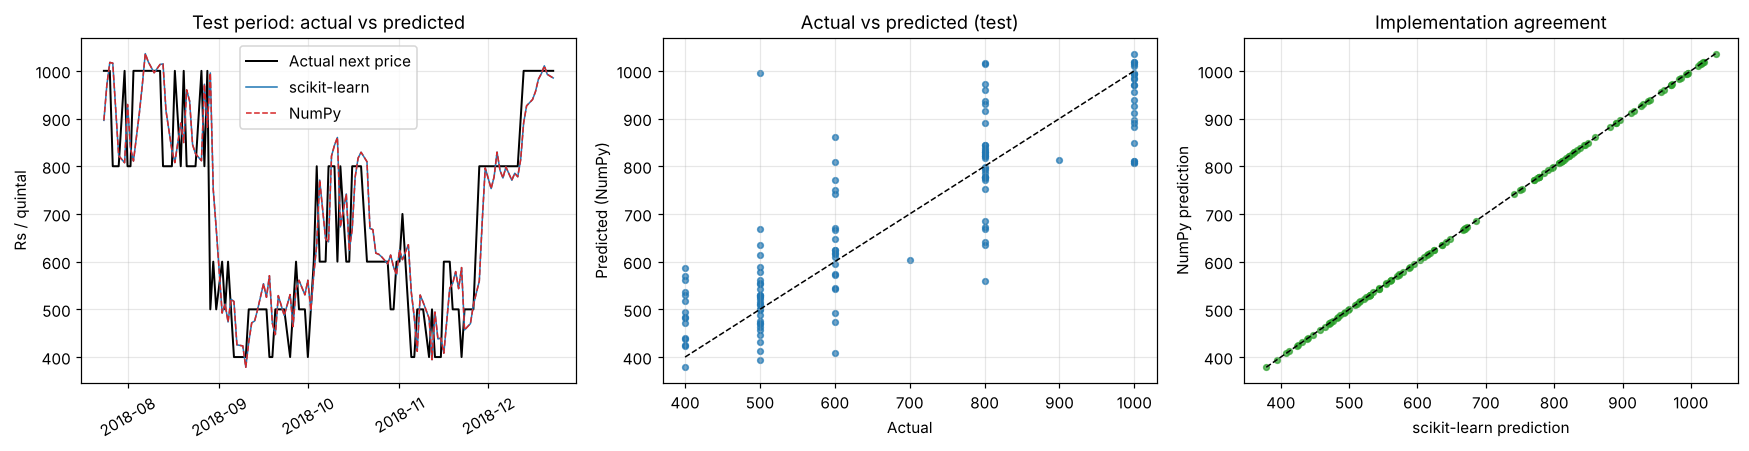

In [14]:
# Plots: predictions vs actual on the TEST period, and a scatter of the two implementations
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].plot(test["observation_date"], yr_test, label="Actual next price", color="black", lw=1.3)
ax[0].plot(test["observation_date"], pred_sk["Test"], label="scikit-learn", color="tab:blue", lw=1)
ax[0].plot(test["observation_date"], pred_np["Test"], "--", label="NumPy", color="tab:red", lw=1)
ax[0].set_title("Test period: actual vs predicted"); ax[0].set_ylabel("Rs / quintal"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(yr_test, pred_np["Test"], s=14, alpha=0.7)
lims = [yr_test.min(), yr_test.max()]
ax[1].plot(lims, lims, "k--", lw=1)
ax[1].set_xlabel("Actual"); ax[1].set_ylabel("Predicted (NumPy)"); ax[1].set_title("Actual vs predicted (test)")

ax[2].scatter(pred_sk["Test"], pred_np["Test"], s=14, alpha=0.7, color="tab:green")
lims = [pred_sk["Test"].min(), pred_sk["Test"].max()]
ax[2].plot(lims, lims, "k--", lw=1)
ax[2].set_xlabel("scikit-learn prediction"); ax[2].set_ylabel("NumPy prediction"); ax[2].set_title("Implementation agreement")
plt.tight_layout(); plt.show()

## Foundation 2: Classification (Logistic Regression): will the price surge by more than 10% in the next 7 days?
### 2.1 Choose the regularisation strength on the validation set

In [15]:
# Try a few regularisation strengths C (smaller C = stronger regularisation) and keep the best
# by validation ROC-AUC. The test set is NOT touched for this choice.
val_rows = []
for C in [10, 1, 0.1, 0.01]:
    m = LogisticRegression(C=C, class_weight="balanced", max_iter=10000).fit(Xc_train_s, yc_train)
    val_rows.append({"C": C, "validation ROC-AUC": roc_auc_score(yc_val, m.predict_proba(Xc_val_s)[:, 1])})
val_table = pd.DataFrame(val_rows)
best_C = float(val_table.loc[val_table["validation ROC-AUC"].idxmax(), "C"])
print(val_table.round(4).to_string(index=False))
print("\nSelected C =", best_C)

    C  validation ROC-AUC
10.00              0.6136
 1.00              0.6158
 0.10              0.6082
 0.01              0.6096

Selected C = 1.0


### 2.2 scikit-learn version

In [16]:
# Ready-made scikit-learn Logistic Regression (class_weight='balanced' handles the minority class)
# tol is tightened so scikit-learn's optimiser runs to (almost) the exact optimum; its default
# tolerance (1e-4) stops slightly early, which would otherwise show up as a tiny coefficient gap.
sk_log = LogisticRegression(C=best_C, class_weight="balanced", max_iter=100000, tol=1e-10)
sk_log.fit(Xc_train_s, yc_train)

proba_sk = {"Train": sk_log.predict_proba(Xc_train_s)[:, 1],
            "Validation": sk_log.predict_proba(Xc_val_s)[:, 1],
            "Test": sk_log.predict_proba(Xc_test_s)[:, 1]}
label_sk = {k: (v >= 0.5).astype(int) for k, v in proba_sk.items()}

### 2.3 NumPy-from-scratch version

In [17]:
# Same algorithm written by hand: batch gradient descent on the weighted, L2-regularised log-loss
theta_log, loss_history = np_logreg_fit(Xc_train_s, yc_train, C=best_C, lr=0.1, n_iter=20000, balanced=True)

proba_np = {"Train": np_logreg_proba(Xc_train_s, theta_log),
            "Validation": np_logreg_proba(Xc_val_s, theta_log),
            "Test": np_logreg_proba(Xc_test_s, theta_log)}
label_np = {k: (v >= 0.5).astype(int) for k, v in proba_np.items()}

print(f"Loss at iteration 1     : {loss_history[0]:.6f}")
print(f"Loss at iteration 20000 : {loss_history[-1]:.6f}")
print(f"Last 100 iterations changed the loss by {abs(loss_history[-100] - loss_history[-1]):.2e}  -> converged")

Loss at iteration 1     : 0.693147
Loss at iteration 20000 : 0.662945
Last 100 iterations changed the loss by 6.86e-13  -> converged


### 2.4 Do both give the same answer?

In [18]:
sk_theta_log = np.r_[sk_log.intercept_, sk_log.coef_[0]]
print(f"Max |coefficient difference|          : {np.abs(sk_theta_log - theta_log).max():.2e}")
print(f"Max |probability difference| (test)   : {np.abs(proba_sk['Test'] - proba_np['Test']).max():.2e}")
print(f"Test labels that agree                : {(label_sk['Test'] == label_np['Test']).mean():.1%}")
print("np.allclose on coefficients (atol=1e-3):", np.allclose(sk_theta_log, theta_log, atol=1e-3))

# Reference: the exact scikit-learn loss for comparison with our gradient-descent loss
coef_table_log = pd.DataFrame({"feature": ["(intercept)"] + CLF_FEATURES,
                               "scikit-learn": sk_theta_log, "NumPy (GD)": theta_log})
coef_table_log["abs difference"] = (coef_table_log["scikit-learn"] - coef_table_log["NumPy (GD)"]).abs()
coef_table_log.round(4)

Max |coefficient difference|          : 4.27e-05
Max |probability difference| (test)   : 1.70e-06
Test labels that agree                : 100.0%
np.allclose on coefficients (atol=1e-3): True


,feature,scikit-learn,NumPy (GD),abs difference
0,(intercept),-0.0406,-0.0406,0.0
1,dev_mean7,-0.4156,-0.4156,0.0
2,cv7,-0.3031,-0.3031,0.0
3,mom7_pct,0.5260,0.5260,0.0
4,chg1_pct,-0.0627,-0.0627,0.0
5,spread_pct,0.2462,0.2462,0.0
6,range7_pct,0.4454,0.4454,0.0
7,arr_dev,-0.1347,-0.1347,0.0
8,arr_chg,-0.3090,-0.3090,0.0
9,is_monsoon_season,-0.2192,-0.2192,0.0


### 2.5 Evaluation (with a majority-class baseline)

In [19]:
rows = []
splits_c = {"Train": yc_train, "Validation": yc_val, "Test": yc_test}
for name, y_true in splits_c.items():
    # Baseline: always predict the majority class (no surge)
    base = np.zeros_like(y_true)
    acc, p, r, f = np_clf_metrics(y_true, base)
    rows.append({"split": name, "model": "Baseline (always 'no surge')", "Accuracy": acc, "Precision": p,
                 "Recall": r, "F1": f, "ROC-AUC": 0.5})
    # scikit-learn metrics for the scikit-learn model
    rows.append({"split": name, "model": "scikit-learn LogisticRegression",
                 "Accuracy": accuracy_score(y_true, label_sk[name]),
                 "Precision": precision_score(y_true, label_sk[name], zero_division=0),
                 "Recall": recall_score(y_true, label_sk[name], zero_division=0),
                 "F1": f1_score(y_true, label_sk[name], zero_division=0),
                 "ROC-AUC": roc_auc_score(y_true, proba_sk[name])})
    # from-scratch metrics for the from-scratch model
    acc, p, r, f = np_clf_metrics(y_true, label_np[name])
    rows.append({"split": name, "model": "NumPy Logistic Regression", "Accuracy": acc, "Precision": p,
                 "Recall": r, "F1": f, "ROC-AUC": np_roc_auc(y_true, proba_np[name])})
clf_results = pd.DataFrame(rows)

# Sanity check that our hand-written metric functions equal scikit-learn's on the same predictions
chk = np_clf_metrics(yc_test, label_sk["Test"])
print("Hand-written metrics match scikit-learn:",
      np.allclose(chk, [accuracy_score(yc_test, label_sk["Test"]), precision_score(yc_test, label_sk["Test"]),
                        recall_score(yc_test, label_sk["Test"]), f1_score(yc_test, label_sk["Test"])]),
      "| AUC match:", np.isclose(np_roc_auc(yc_test, proba_sk["Test"]), roc_auc_score(yc_test, proba_sk["Test"])))
clf_results.round(3)

Hand-written metrics match scikit-learn: True | AUC match: True


,split,model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Train,Baseline (always 'no surge'),0.659,0.000,0.000,0.000,0.500
1,Train,scikit-learn LogisticRegression,0.598,0.429,0.538,0.478,0.641
2,Train,NumPy Logistic Regression,0.598,0.429,0.538,0.478,0.641
3,Validation,Baseline (always 'no surge'),0.677,0.000,0.000,0.000,0.500
4,Validation,scikit-learn LogisticRegression,0.592,0.415,0.643,0.505,0.616
5,Validation,NumPy Logistic Regression,0.592,0.415,0.643,0.505,0.616
6,Test,Baseline (always 'no surge'),0.675,0.000,0.000,0.000,0.500
7,Test,scikit-learn LogisticRegression,0.627,0.364,0.195,0.254,0.636
8,Test,NumPy Logistic Regression,0.627,0.364,0.195,0.254,0.636


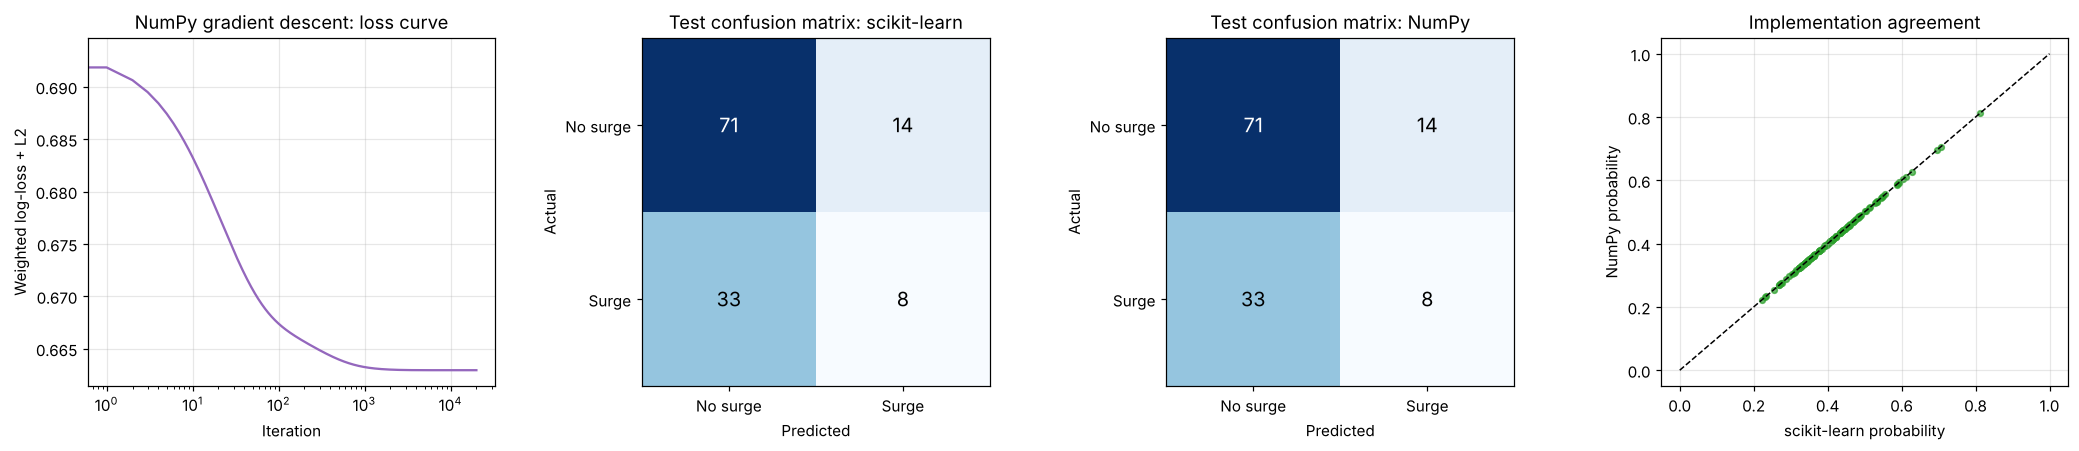

In [20]:
# Plots: loss curve, confusion matrices (test), and implementation agreement
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))

ax[0].plot(loss_history, color="tab:purple")
ax[0].set_xscale("log"); ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Weighted log-loss + L2")
ax[0].set_title("NumPy gradient descent: loss curve")

for k, (title, labels) in enumerate([("scikit-learn", label_sk["Test"]), ("NumPy", label_np["Test"])], start=1):
    cm = np_confusion(yc_test, labels)
    ax[k].imshow(cm, cmap="Blues")
    ax[k].set_xticks([0, 1]); ax[k].set_yticks([0, 1])
    ax[k].set_xticklabels(["No surge", "Surge"]); ax[k].set_yticklabels(["No surge", "Surge"])
    ax[k].set_xlabel("Predicted"); ax[k].set_ylabel("Actual"); ax[k].set_title(f"Test confusion matrix: {title}")
    ax[k].grid(False)
    for i in range(2):
        for j in range(2):
            ax[k].text(j, i, int(cm[i, j]), ha="center", va="center",
                       color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)

ax[3].scatter(proba_sk["Test"], proba_np["Test"], s=14, alpha=0.7, color="tab:green")
ax[3].plot([0, 1], [0, 1], "k--", lw=1)
ax[3].set_xlabel("scikit-learn probability"); ax[3].set_ylabel("NumPy probability"); ax[3].set_title("Implementation agreement")
plt.tight_layout(); plt.show()

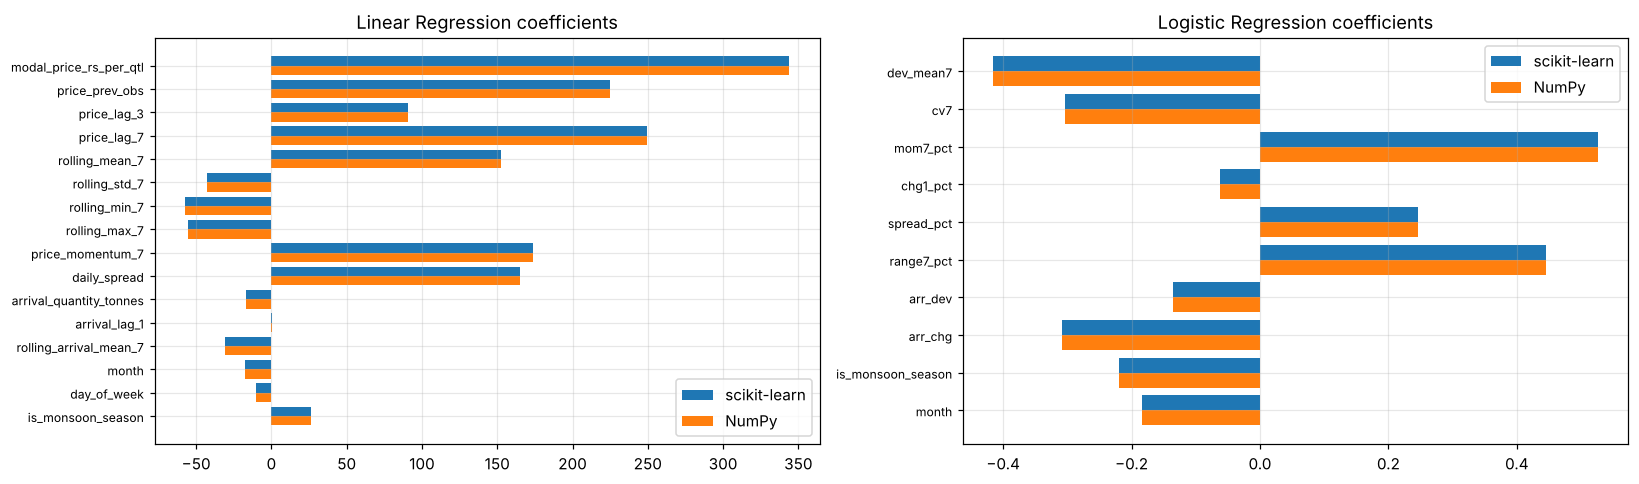

In [21]:
# Side-by-side coefficient comparison for both models (standardised features)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, tbl, col2, title in [(ax[0], coef_table.iloc[1:], "NumPy", "Linear Regression coefficients"),
                            (ax[1], coef_table_log.iloc[1:], "NumPy (GD)", "Logistic Regression coefficients")]:
    pos = np.arange(len(tbl))
    a.barh(pos - 0.2, tbl["scikit-learn"], height=0.4, label="scikit-learn")
    a.barh(pos + 0.2, tbl[col2], height=0.4, label="NumPy")
    a.set_yticks(pos); a.set_yticklabels(tbl["feature"], fontsize=8); a.invert_yaxis()
    a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

### 7.8 Final side-by-side summary

In [22]:
final = pd.DataFrame({
    "Linear Regression (test)": {
        "scikit-learn MAE":  mean_absolute_error(yr_test, pred_sk["Test"]),
        "NumPy MAE":         np_mae(yr_test, pred_np["Test"]),
        "scikit-learn RMSE": mean_squared_error(yr_test, pred_sk["Test"]) ** 0.5,
        "NumPy RMSE":        np_rmse(yr_test, pred_np["Test"]),
        "scikit-learn R2":   r2_score(yr_test, pred_sk["Test"]),
        "NumPy R2":          np_r2(yr_test, pred_np["Test"]),
    }})
print(final.round(4).to_string())
print()
final_c = pd.DataFrame({
    "Logistic Regression (test)": {
        "scikit-learn Accuracy": accuracy_score(yc_test, label_sk["Test"]),
        "NumPy Accuracy":        np_clf_metrics(yc_test, label_np["Test"])[0],
        "scikit-learn F1":       f1_score(yc_test, label_sk["Test"]),
        "NumPy F1":              np_clf_metrics(yc_test, label_np["Test"])[3],
        "scikit-learn ROC-AUC":  roc_auc_score(yc_test, proba_sk["Test"]),
        "NumPy ROC-AUC":         np_roc_auc(yc_test, proba_np["Test"]),
    }})
print(final_c.round(4).to_string())

                   Linear Regression (test)
scikit-learn MAE                    77.1282
NumPy MAE                           77.1282
scikit-learn RMSE                  106.5615
NumPy RMSE                         106.5615
scikit-learn R2                      0.7287
NumPy R2                             0.7287

                       Logistic Regression (test)
scikit-learn Accuracy                      0.6270
NumPy Accuracy                             0.6270
scikit-learn F1                            0.2540
NumPy F1                                   0.2540
scikit-learn ROC-AUC                       0.6359
NumPy ROC-AUC                              0.6359


---
## Part A: Classification using scikit-learn
**Task (same as before):** will the Pune tomato price rise by more than 10% within the next 7 days? (`surge_7d`, 1 = surge)

Models: **SVM** (RBF and linear kernels), **Decision Tree Classifier**, **KNN Classifier**, **Gaussian Naive Bayes**.
Evaluation: Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC and **time-series cross-validation**.

How the models are tuned and judged:
* Each model's one key hyper-parameter is chosen on the **validation** set by ROC-AUC (a threshold-free score), so the test set is never used for tuning.
* **Cross-validation** uses `TimeSeriesSplit` (expanding window: always train on the past, validate on the next block) on Train + Validation. Normal shuffled k-fold would leak future prices into training. Scaling is done *inside* each fold with a `Pipeline`.
* Test metrics use the default 0.5 decision threshold (SVMs use the sign of the decision function).

In [23]:
# ---- Additional imports for Parts A-F ------------------------------------------------------
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import roc_curve
from sklearn.inspection import permutation_importance

RS = 42   # one random seed for every stochastic model, so the notebook is reproducible

def clf_scores(y, label, score):
    """All five classification metrics in one dictionary."""
    return {"Accuracy":  accuracy_score(y, label),
            "Precision": precision_score(y, label, zero_division=0),
            "Recall":    recall_score(y, label, zero_division=0),
            "F1":        f1_score(y, label, zero_division=0),
            "ROC-AUC":   roc_auc_score(y, score)}

def continuous_score(model, X):
    """Probability of class 1 if available, otherwise the SVM decision-function value."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

In [24]:
# ---- Model definitions: (constructor taking the tuned hyper-parameter, grid of values to try) --
clf_specs = {
    "SVM (RBF kernel)":     dict(param="C",         grid=[0.1, 1, 10],
                                 make=lambda v: SVC(kernel="rbf", C=v, gamma="scale", class_weight="balanced")),
    "SVM (linear kernel)":  dict(param="C",         grid=[0.01, 0.1, 1],
                                 make=lambda v: SVC(kernel="linear", C=v, class_weight="balanced")),
    "Decision Tree":        dict(param="max_depth", grid=[2, 3, 4, 5, 6, 8],
                                 make=lambda v: DecisionTreeClassifier(max_depth=v, min_samples_leaf=10,
                                                                       class_weight="balanced", random_state=RS)),
    "KNN":                  dict(param="k",         grid=[5, 11, 21, 31, 51],
                                 make=lambda v: KNeighborsClassifier(n_neighbors=v)),
    "Gaussian Naive Bayes": dict(param="-",         grid=[None],
                                 make=lambda v: GaussianNB()),
}

clf_store = {}      # everything we need later: fitted model, best parameter, scores, labels
tuning_rows = []
for name, spec in clf_specs.items():
    # 1) tune on validation ROC-AUC
    best_v, best_auc = None, -1
    for v in spec["grid"]:
        m = spec["make"](v).fit(Xc_train_s, yc_train)
        auc = roc_auc_score(yc_val, continuous_score(m, Xc_val_s))
        tuning_rows.append({"model": name, spec["param"]: v, "validation ROC-AUC": auc})
        if auc > best_auc:
            best_v, best_auc = v, auc
    # 2) refit the best configuration on the training set and score all splits
    model = spec["make"](best_v).fit(Xc_train_s, yc_train)
    clf_store[name] = {"model": model, "param": best_v, "val_auc": best_auc,
                       "val_score":  continuous_score(model, Xc_val_s),
                       "test_score": continuous_score(model, Xc_test_s),
                       "test_label": model.predict(Xc_test_s)}

print("Selected hyper-parameters (by validation ROC-AUC):")
for n, d in clf_store.items():
    print(f"  {n:22s} {clf_specs[n]['param']:>9s} = {d['param']}   (validation AUC {d['val_auc']:.3f})")

Selected hyper-parameters (by validation ROC-AUC):
  SVM (RBF kernel)               C = 1   (validation AUC 0.716)
  SVM (linear kernel)            C = 1   (validation AUC 0.627)
  Decision Tree          max_depth = 3   (validation AUC 0.626)
  KNN                            k = 51   (validation AUC 0.658)
  Gaussian Naive Bayes           - = None   (validation AUC 0.608)


### A.1 Test-set evaluation

In [25]:
rows = []
for name, d in clf_store.items():
    rows.append({"model": name, **clf_scores(yc_test, d["test_label"], d["test_score"])})
# Foundation model (Logistic Regression, already fitted above) for reference
rows.append({"model": "Logistic Regression (Foundation)", **clf_scores(yc_test, label_sk["Test"], proba_sk["Test"])})
partA_table = pd.DataFrame(rows).set_index("model")
print(f"Test set: {len(yc_test)} rows, {yc_test.sum()} real surges "
      f"-> 'always no surge' would score accuracy {1 - yc_test.mean():.3f}")
partA_table.round(3)

Test set: 126 rows, 41 real surges -> 'always no surge' would score accuracy 0.675


,Accuracy,Precision,Recall,F1,ROC-AUC
model,,,,,
SVM (RBF kernel),0.548,0.289,0.268,0.278,0.476
SVM (linear kernel),0.643,0.333,0.098,0.151,0.555
Decision Tree,0.460,0.245,0.317,0.277,0.333
KNN,0.667,0.000,0.000,0.000,0.432
Gaussian Naive Bayes,0.310,0.315,0.951,0.473,0.443
Logistic Regression (Foundation),0.627,0.364,0.195,0.254,0.636


### A.2 Confusion matrices and ROC curves (test set)

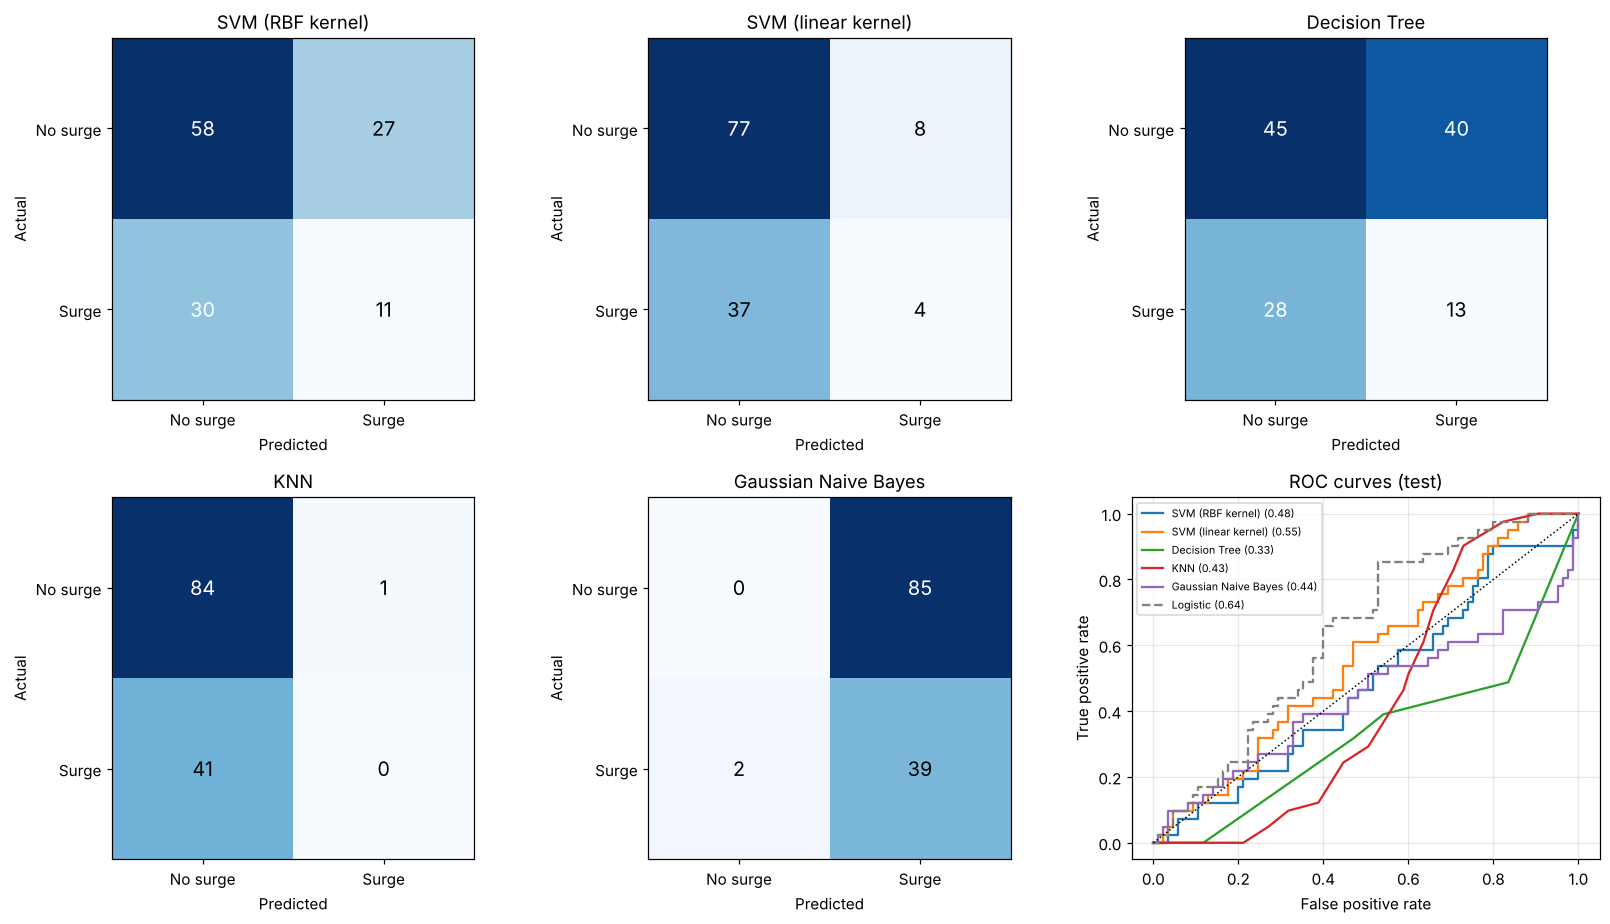

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
names = list(clf_store.keys())
for ax, name in zip(axes.ravel(), names):
    cm = confusion_matrix(yc_test, clf_store[name]["test_label"])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["No surge", "Surge"]); ax.set_yticklabels(["No surge", "Surge"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

# ROC curves in the sixth panel
ax = axes.ravel()[5]
for name in names:
    fpr, tpr, _ = roc_curve(yc_test, clf_store[name]["test_score"])
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(yc_test, clf_store[name]['test_score']):.2f})")
fpr, tpr, _ = roc_curve(yc_test, proba_sk["Test"])
ax.plot(fpr, tpr, "--", color="grey", label=f"Logistic ({roc_auc_score(yc_test, proba_sk['Test']):.2f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves (test)")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### A.3 Time-series cross-validation (Train + Validation, 5 expanding-window folds)

In [27]:
# Stack Train + Validation in time order. Scaling happens inside each fold (Pipeline) -> no leakage.
Xc_trval = np.vstack([Xc_train, Xc_val]);  yc_trval = np.r_[yc_train, yc_val]
tscv = TimeSeriesSplit(n_splits=5)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}

cv_models = {n: d["model"] for n, d in clf_store.items()}
cv_models["Logistic Regression (Foundation)"] = LogisticRegression(C=best_C, class_weight="balanced", max_iter=10000)

cv_rows, cv_auc = [], {}
for name, model in cv_models.items():
    pipe = make_pipeline(StandardScaler(), model)          # a fresh clone is fitted inside every fold
    res = cross_validate(pipe, Xc_trval, yc_trval, cv=tscv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        vals = res["test_" + metric]
        row[metric] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    cv_rows.append(row)
    cv_auc[name] = res["test_ROC-AUC"].mean()
pd.DataFrame(cv_rows).set_index("model")

,Accuracy,Precision,Recall,F1,ROC-AUC
model,,,,,
SVM (RBF kernel),0.530 ± 0.044,0.366 ± 0.052,0.627 ± 0.193,0.442 ± 0.039,0.630 ± 0.096
SVM (linear kernel),0.442 ± 0.104,0.325 ± 0.081,0.658 ± 0.283,0.406 ± 0.063,0.591 ± 0.060
Decision Tree,0.528 ± 0.071,0.346 ± 0.088,0.554 ± 0.282,0.388 ± 0.111,0.579 ± 0.068
KNN,0.607 ± 0.104,0.417 ± 0.126,0.291 ± 0.326,0.239 ± 0.119,0.610 ± 0.073
Gaussian Naive Bayes,0.426 ± 0.140,0.263 ± 0.133,0.667 ± 0.422,0.358 ± 0.186,0.564 ± 0.039
Logistic Regression (Foundation),0.494 ± 0.105,0.357 ± 0.075,0.633 ± 0.235,0.424 ± 0.045,0.588 ± 0.051


---
## Part B: Classification from scratch (NumPy only)
Four classifiers are written by hand and compared with Part A (same hyper-parameters, same data):

| Algorithm | Core idea | Compared with |
|---|---|---|
| **KNN** | Euclidean distance to all training points, vote of the k closest | `KNeighborsClassifier` |
| **Gaussian Naive Bayes** | class prior × product of per-feature normal densities, in log space | `GaussianNB` |
| **Decision Tree** | greedy search of the split (feature, threshold) with the best weighted Gini decrease, recursive | `DecisionTreeClassifier` |
| **Linear SVM** | minimise $\tfrac12\|w\|^2 + C\sum_i s_i\max(0,\,1-y_i(w\cdot x_i+b))$ by (sub)gradient descent | `SVC(kernel="linear")` |

The first three are deterministic, so they should reproduce scikit-learn almost exactly. The SVM is solved iteratively (scikit-learn solves its dual problem exactly), so we expect a close but not perfect match.

In [28]:
# ------------------------------------------------------------------------------------------
# 1) K-Nearest Neighbours (classification AND regression share the neighbour search)
# ------------------------------------------------------------------------------------------
class NumpyKNN:
    def __init__(self, k=5, task="clf"):
        self.k, self.task = k, task

    def fit(self, X, y):
        self.X_, self.y_ = np.asarray(X, float), np.asarray(y, float)   # KNN just memorises the data
        return self

    def _neighbour_targets(self, X):
        # Pairwise Euclidean distances: shape (n_query, n_train)
        d = np.sqrt(((X[:, None, :] - self.X_[None, :, :]) ** 2).sum(axis=2))
        idx = np.argsort(d, axis=1, kind="stable")[:, :self.k]          # indices of the k nearest points
        return self.y_[idx]                                              # targets of those neighbours

    def predict_proba(self, X):
        """Classification: share of the k neighbours that belong to class 1."""
        return self._neighbour_targets(np.asarray(X, float)).mean(axis=1)

    def predict(self, X):
        nb = self._neighbour_targets(np.asarray(X, float))
        if self.task == "clf":
            return (nb.mean(axis=1) > 0.5).astype(int)                   # majority vote (k is odd)
        return nb.mean(axis=1)                                           # regression: average of neighbours

# ------------------------------------------------------------------------------------------
# 2) Gaussian Naive Bayes
# ------------------------------------------------------------------------------------------
class NumpyGaussianNB:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, float)
        self.classes_ = np.unique(y)
        self.prior_ = np.array([np.mean(y == c) for c in self.classes_])             # P(class)
        self.mean_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])       # per-class feature means
        self.var_ = np.array([X[y == c].var(axis=0) for c in self.classes_])         # per-class feature variances
        self.var_ += self.var_smoothing * X.var(axis=0).max()                        # avoid division by ~0
        return self

    def _log_joint(self, X):
        X = np.asarray(X, float)
        out = []
        for c in range(len(self.classes_)):
            # log P(class) + sum_j log N(x_j | mean_cj, var_cj)
            log_lik = -0.5 * np.sum(np.log(2 * np.pi * self.var_[c]) + (X - self.mean_[c]) ** 2 / self.var_[c], axis=1)
            out.append(np.log(self.prior_[c]) + log_lik)
        return np.array(out).T

    def predict_proba(self, X):
        jl = self._log_joint(X)
        jl -= jl.max(axis=1, keepdims=True)                 # log-sum-exp trick for numerical stability
        p = np.exp(jl)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self._log_joint(X), axis=1)]

# ------------------------------------------------------------------------------------------
# 3) Decision tree (CART). One class serves classification (Gini) and regression (squared error)
# ------------------------------------------------------------------------------------------
class NumpyDecisionTree:
    def __init__(self, task="clf", max_depth=5, min_samples_leaf=1, balanced=False):
        self.task, self.max_depth, self.min_samples_leaf, self.balanced = task, max_depth, min_samples_leaf, balanced

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        if self.task == "clf" and self.balanced:             # class_weight="balanced": n / (2 * n_class)
            n1 = y.sum(); n0 = len(y) - n1
            w = np.where(y == 1, len(y) / (2 * n1), len(y) / (2 * n0))
        else:
            w = np.ones(len(y))
        self.importances_ = np.zeros(X.shape[1])             # total impurity decrease contributed by each feature
        self.root_ = self._grow(X, y, w, depth=0)
        self.importances_ /= max(self.importances_.sum(), 1e-12)
        return self

    def _cost(self, W, S, Q):
        """Weighted impurity 'cost' of a node from cumulative sums (W = sum w, S = sum w*y, Q = sum w*y^2)."""
        if self.task == "clf":
            p = S / W
            return W * 2 * p * (1 - p)                       # weighted Gini impurity (binary)
        return Q - S ** 2 / W                                # weighted sum of squared errors

    def _best_split(self, X, y, w):
        n, p = X.shape
        best = (None, None, 1e-12)                           # (feature, threshold, gain) - must beat 1e-12
        W, S, Q = w.sum(), (w * y).sum(), (w * y * y).sum()
        parent_cost = self._cost(W, S, Q)
        for j in range(p):
            order = np.argsort(X[:, j], kind="stable")
            xs, ws, ys = X[order, j], w[order], y[order]
            Wl, Sl, Ql = np.cumsum(ws)[:-1], np.cumsum(ws * ys)[:-1], np.cumsum(ws * ys * ys)[:-1]
            Wr, Sr, Qr = W - Wl, S - Sl, Q - Ql
            gain = parent_cost - (self._cost(Wl, Sl, Ql) + self._cost(Wr, Sr, Qr))
            # a split is allowed only between two different values, and both children need enough samples
            n_left = np.arange(1, n)
            valid = (xs[:-1] != xs[1:]) & (n_left >= self.min_samples_leaf) & (n - n_left >= self.min_samples_leaf)
            gain = np.where(valid, gain, -np.inf)
            i = int(np.argmax(gain))
            if gain[i] > best[2]:
                best = (j, (xs[i] + xs[i + 1]) / 2, gain[i])  # threshold = midpoint between neighbouring values
        return best

    def _grow(self, X, y, w, depth):
        node = {"value": np.sum(w * y) / np.sum(w)}          # leaf output: weighted class-1 share / mean
        if depth >= self.max_depth or len(y) < 2 * self.min_samples_leaf or np.all(y == y[0]):
            return node
        j, thr, gain = self._best_split(X, y, w)
        if j is None:
            return node
        self.importances_[j] += gain
        left = X[:, j] <= thr
        node.update(feature=j, threshold=thr,
                    left=self._grow(X[left], y[left], w[left], depth + 1),
                    right=self._grow(X[~left], y[~left], w[~left], depth + 1))
        return node

    def _predict_value(self, X):
        out = np.empty(len(X))
        for i, x in enumerate(np.asarray(X, float)):
            node = self.root_
            while "feature" in node:                         # walk down until a leaf is reached
                node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
            out[i] = node["value"]
        return out

    def predict_proba(self, X):
        return self._predict_value(X)

    def predict(self, X):
        v = self._predict_value(X)
        return (v > 0.5).astype(int) if self.task == "clf" else v

# ------------------------------------------------------------------------------------------
# 4) Linear SVM trained with sub-gradient descent on the hinge loss
# ------------------------------------------------------------------------------------------
def np_linear_svm_fit(X, y01, C=1.0, n_iter=20000, lr0=2.0, balanced=True):
    """
    Minimise   0.5*||w||^2 + C * sum_i s_i * max(0, 1 - y_i (w.x_i + b))   with labels y in {-1,+1}.
    The objective is divided by C*sum(s) so the step sizes are well scaled:
        J = lam/2 ||w||^2 + (1/sum s) sum_i s_i hinge_i ,   lam = 1/(C*sum s)
    The hinge loss is not differentiable at the kink, so we use a sub-gradient. Because J is strongly convex
    (thanks to the lam/2 ||w||^2 term) the step size lr0 / (1 + lr0*lam*t) is used, which shrinks like 1/t.
    The average of the second half of the iterates is returned (smooths the zig-zag around the optimum).
    """
    y = 2.0 * y01 - 1.0
    if balanced:
        n1 = y01.sum(); n0 = len(y01) - n1
        s = np.where(y01 == 1, len(y01) / (2 * n1), len(y01) / (2 * n0))
    else:
        s = np.ones(len(y))
    s_sum, lam = s.sum(), 1.0 / (C * s.sum())
    w, b = np.zeros(X.shape[1]), 0.0
    w_avg, b_avg, n_avg = np.zeros_like(w), 0.0, 0
    history = []
    for t in range(1, n_iter + 1):
        margin = y * (X @ w + b)
        viol = margin < 1                                    # points inside the margin or misclassified
        g_w = lam * w - (X[viol].T @ (s[viol] * y[viol])) / s_sum
        g_b = -np.sum(s[viol] * y[viol]) / s_sum
        step = lr0 / (1 + lr0 * lam * t)
        w, b = w - step * g_w, b - step * g_b
        history.append(0.5 * lam * w @ w + np.sum(s * np.maximum(0, 1 - y * (X @ w + b))) / s_sum)
        if t > n_iter // 2:                                  # average the second half of the iterates
            n_avg += 1
            w_avg += (w - w_avg) / n_avg
            b_avg += (b - b_avg) / n_avg
    return w_avg, b_avg, np.array(history)

def svm_objective(X, y01, w, b, C):
    """The same regularised, class-weighted hinge objective, so any (w, b) can be scored on equal terms."""
    y = 2.0 * y01 - 1.0
    n1 = y01.sum(); n0 = len(y01) - n1
    s = np.where(y01 == 1, len(y01) / (2 * n1), len(y01) / (2 * n0))
    return 0.5 / (C * s.sum()) * w @ w + np.sum(s * np.maximum(0, 1 - y * (X @ w + b))) / s.sum()

def np_svm_decision(X, w, b):
    return X @ w + b

In [29]:
# ---- Fit the four from-scratch models with the SAME hyper-parameters chosen in Part A ----------
k_best     = clf_store["KNN"]["param"]
depth_best = clf_store["Decision Tree"]["param"]
C_lin_best = clf_store["SVM (linear kernel)"]["param"]

scratch_clf = {}
# KNN
m = NumpyKNN(k=k_best, task="clf").fit(Xc_train_s, yc_train)
scratch_clf["KNN"] = {"model": m, "val_score": m.predict_proba(Xc_val_s), "test_score": m.predict_proba(Xc_test_s),
                      "test_label": m.predict(Xc_test_s)}
# Gaussian NB
m = NumpyGaussianNB().fit(Xc_train_s, yc_train)
scratch_clf["Gaussian Naive Bayes"] = {"model": m, "val_score": m.predict_proba(Xc_val_s)[:, 1],
                                       "test_score": m.predict_proba(Xc_test_s)[:, 1],
                                       "test_label": m.predict(Xc_test_s)}
# Decision tree (balanced class weights, same depth and leaf size as the sklearn tree)
m = NumpyDecisionTree("clf", max_depth=depth_best, min_samples_leaf=10, balanced=True).fit(Xc_train_s, yc_train)
scratch_clf["Decision Tree"] = {"model": m, "val_score": m.predict_proba(Xc_val_s), "test_score": m.predict_proba(Xc_test_s),
                                "test_label": m.predict(Xc_test_s)}
# Linear SVM by sub-gradient descent
w_svm, b_svm, svm_hist = np_linear_svm_fit(Xc_train_s, yc_train, C=C_lin_best)
dec_val, dec_test = np_svm_decision(Xc_val_s, w_svm, b_svm), np_svm_decision(Xc_test_s, w_svm, b_svm)
scratch_clf["SVM (linear kernel)"] = {"model": (w_svm, b_svm), "val_score": dec_val, "test_score": dec_test,
                                      "test_label": (dec_test > 0).astype(int)}
print(f"Linear SVM objective: first iteration {svm_hist[0]:.4f} -> last {svm_hist[-1]:.4f}")

Linear SVM objective: first iteration 0.9125 -> last 0.8646


### B.1 From-scratch vs scikit-learn (test set)

In [30]:
rows = []
for name, sc in scratch_clf.items():
    sk = clf_store[name]
    m_sk = clf_scores(yc_test, sk["test_label"], sk["test_score"])
    m_np = clf_scores(yc_test, sc["test_label"], sc["test_score"])
    # For probability models also compare the raw outputs; for the SVM compare the decision values
    gap = np.abs(sk["test_score"] - sc["test_score"]).max()
    rows.append({"algorithm": name,
                 "label agreement": f"{(sk['test_label'] == sc['test_label']).mean():.1%}",
                 "max |score diff|": f"{gap:.2e}",
                 "sklearn Acc": m_sk["Accuracy"], "NumPy Acc": m_np["Accuracy"],
                 "sklearn F1": m_sk["F1"], "NumPy F1": m_np["F1"],
                 "sklearn AUC": m_sk["ROC-AUC"], "NumPy AUC": m_np["ROC-AUC"]})
partB_table = pd.DataFrame(rows).set_index("algorithm")
partB_table.round(4)

,label agreement,max |score diff|,sklearn Acc,NumPy Acc,sklearn F1,NumPy F1,sklearn AUC,NumPy AUC
algorithm,,,,,,,,
KNN,100.0%,0.00e+00,0.6667,0.6667,0.0000,0.0000,0.4317,0.4317
Gaussian Naive Bayes,100.0%,2.00e-15,0.3095,0.3095,0.4727,0.4727,0.4428,0.4428
Decision Tree,100.0%,2.75e-03,0.4603,0.4603,0.2766,0.2766,0.3326,0.3326
SVM (linear kernel),100.0%,3.62e-03,0.6429,0.6429,0.1509,0.1509,0.5549,0.5552


Max |importance difference|: 0.008348

Linear SVM weights (standardised features):
          feature  sklearn SVC  NumPy sub-gradient
        dev_mean7       -0.574              -0.574
              cv7       -0.223              -0.223
         mom7_pct        0.776               0.776
         chg1_pct       -0.059              -0.060
       spread_pct        0.272               0.272
       range7_pct        0.545               0.544
          arr_dev       -0.145              -0.146
          arr_chg       -0.506              -0.500
is_monsoon_season       -0.314              -0.314
            month       -0.421              -0.422

Objective value on the training set -> scikit-learn solution: 0.86455 | NumPy solution: 0.86455
Correlation of decision values (test): 1.0


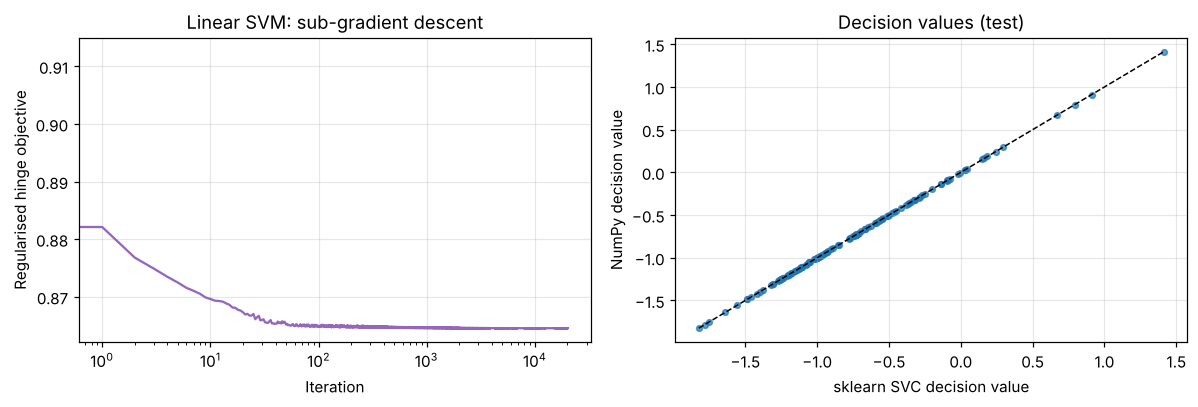

In [31]:
# Extra checks on the structure of the scratch models
# 1) Decision-tree feature importances (our implementation vs scikit-learn)
imp = pd.DataFrame({"feature": CLF_FEATURES,
                    "sklearn tree": clf_store["Decision Tree"]["model"].feature_importances_,
                    "NumPy tree": scratch_clf["Decision Tree"]["model"].importances_})
print("Max |importance difference|:", np.abs(imp["sklearn tree"] - imp["NumPy tree"]).max().round(6))

# 2) Linear SVM: weight vectors and how well the sign of the decision function agrees
w_sk = clf_store["SVM (linear kernel)"]["model"].coef_[0]
print("\nLinear SVM weights (standardised features):")
print(pd.DataFrame({"feature": CLF_FEATURES, "sklearn SVC": w_sk, "NumPy sub-gradient": w_svm}).round(3).to_string(index=False))
b_sk = clf_store["SVM (linear kernel)"]["model"].intercept_[0]
print(f"\nObjective value on the training set -> scikit-learn solution: {svm_objective(Xc_train_s, yc_train, w_sk, b_sk, C_lin_best):.5f}"
      f" | NumPy solution: {svm_objective(Xc_train_s, yc_train, w_svm, b_svm, C_lin_best):.5f}")
print("Correlation of decision values (test):",
      np.corrcoef(clf_store["SVM (linear kernel)"]["test_score"], dec_test)[0, 1].round(4))

# Plot: SVM objective during training and the two decision-value sets
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(svm_hist, color="tab:purple"); ax[0].set_xscale("log")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Regularised hinge objective"); ax[0].set_title("Linear SVM: sub-gradient descent")
ax[1].scatter(clf_store["SVM (linear kernel)"]["test_score"], dec_test, s=14, alpha=0.7)
lims = [dec_test.min(), dec_test.max()]; ax[1].plot(lims, lims, "k--", lw=1)
ax[1].set_xlabel("sklearn SVC decision value"); ax[1].set_ylabel("NumPy decision value"); ax[1].set_title("Decision values (test)")
plt.tight_layout(); plt.show()

---
## Part C: Regression using scikit-learn
**Task:** predict the next modal price of tomato in Pune (Rs/quintal) from price history, volatility and arrival features (`REG_FEATURES`, standardised).

Models: **Linear, Ridge, Lasso, Decision Tree, KNN and Random Forest Regressors**. Ridge ($\alpha$), Lasso ($\alpha$), tree depth, $k$ and forest depth are chosen on the validation set by RMSE.
Metrics: **MAE, MSE, RMSE and R²**. As before the naive rule "tomorrow = today" is the baseline to beat.

* **Ridge** adds an L2 penalty $\alpha\|\theta\|^2$ (shrinks correlated coefficients).
* **Lasso** adds an L1 penalty $\alpha\|\theta\|_1$ (can set coefficients exactly to zero, i.e. it selects features).
* **Decision Tree / Random Forest** split the feature space into boxes and predict the average price in each box. They cannot extrapolate beyond prices seen in training.

In [32]:
def reg_scores(y, p):
    """The four regression metrics."""
    mse_ = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "MSE": mse_, "RMSE": np.sqrt(mse_), "R2": r2_score(y, p)}

reg_specs = {
    "Linear Regression":      dict(param="-",         grid=[None], make=lambda v: LinearRegression()),
    "Ridge Regression":       dict(param="alpha",     grid=[0.1, 1, 10, 100, 1000], make=lambda v: Ridge(alpha=v)),
    "Lasso Regression":       dict(param="alpha",     grid=[0.1, 1, 5, 10, 30], make=lambda v: Lasso(alpha=v, max_iter=100000)),
    "Decision Tree":          dict(param="max_depth", grid=[2, 3, 4, 5, 6, 8],
                                   make=lambda v: DecisionTreeRegressor(max_depth=v, min_samples_leaf=5, random_state=RS)),
    "KNN":                    dict(param="k",         grid=[3, 5, 7, 11, 15, 21], make=lambda v: KNeighborsRegressor(n_neighbors=v)),
    "Random Forest":          dict(param="max_depth", grid=[4, 6, 8, None],
                                   make=lambda v: RandomForestRegressor(n_estimators=300, max_depth=v, min_samples_leaf=3,
                                                                        random_state=RS, n_jobs=-1)),
}

reg_store = {}
for name, spec in reg_specs.items():
    best_v, best_rmse = None, np.inf
    for v in spec["grid"]:                                   # tune on validation RMSE
        m = spec["make"](v).fit(Xr_train_s, yr_train)
        rmse = reg_scores(yr_val, m.predict(Xr_val_s))["RMSE"]
        if rmse < best_rmse:
            best_v, best_rmse = v, rmse
    model = spec["make"](best_v).fit(Xr_train_s, yr_train)
    reg_store[name] = {"model": model, "param": best_v, "val_pred": model.predict(Xr_val_s),
                       "test_pred": model.predict(Xr_test_s), "train_pred": model.predict(Xr_train_s)}

print("Selected hyper-parameters (by validation RMSE):")
for n, d in reg_store.items():
    print(f"  {n:18s} {reg_specs[n]['param']:>9s} = {d['param']}")
lasso_m = reg_store["Lasso Regression"]["model"]
print("\nLasso kept", int((lasso_m.coef_ != 0).sum()), "of", len(REG_FEATURES), "features:",
      [f for f, c in zip(REG_FEATURES, lasso_m.coef_) if c != 0])

Selected hyper-parameters (by validation RMSE):
  Linear Regression          - = None
  Ridge Regression       alpha = 0.1
  Lasso Regression       alpha = 10
  Decision Tree      max_depth = 4
  KNN                        k = 21
  Random Forest      max_depth = 6

Lasso kept 10 of 16 features: ['modal_price_rs_per_qtl', 'price_prev_obs', 'price_lag_3', 'rolling_min_7', 'price_momentum_7', 'daily_spread', 'arrival_quantity_tonnes', 'rolling_arrival_mean_7', 'month', 'is_monsoon_season']


### C.1 Test-set evaluation

In [33]:
naive_test = test["modal_price_rs_per_qtl"].values
rows = [{"model": "Naive (tomorrow = today)", **reg_scores(yr_test, naive_test)}]
for name, d in reg_store.items():
    rows.append({"model": name, **reg_scores(yr_test, d["test_pred"])})
partC_table = pd.DataFrame(rows).set_index("model")
partC_table.round(3)

,MAE,MSE,RMSE,R2
model,,,,
Naive (tomorrow = today),66.667,12380.952,111.270,0.704
Linear Regression,77.128,11355.355,106.562,0.729
Ridge Regression,77.109,11351.746,106.545,0.729
Lasso Regression,75.128,10789.913,103.875,0.742
Decision Tree,104.329,19150.486,138.385,0.543
KNN,162.158,35773.324,189.138,0.145
Random Forest,95.441,17178.787,131.068,0.590


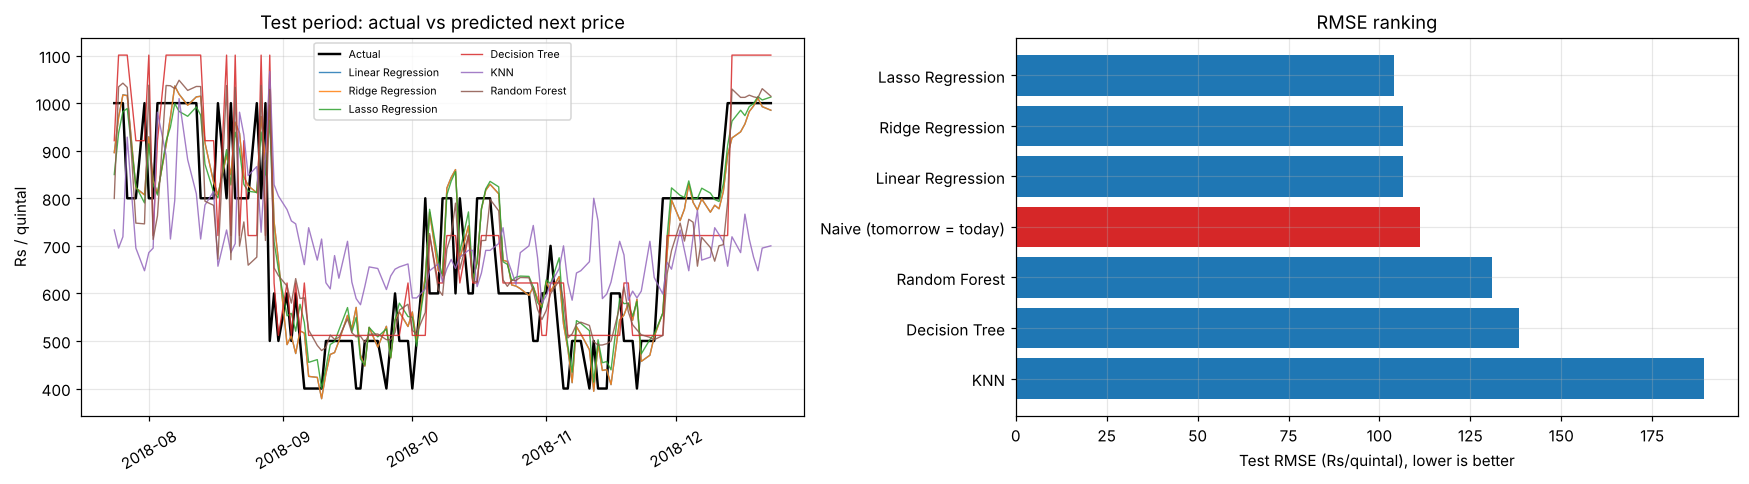

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].plot(test["observation_date"], yr_test, color="black", lw=1.6, label="Actual")
for name, d in reg_store.items():
    ax[0].plot(test["observation_date"], d["test_pred"], lw=0.9, alpha=0.85, label=name)
ax[0].set_title("Test period: actual vs predicted next price"); ax[0].set_ylabel("Rs / quintal")
ax[0].tick_params(axis="x", rotation=30); ax[0].legend(fontsize=7, ncol=2)

order = partC_table["RMSE"].sort_values()
ax[1].barh(order.index, order.values, color=["tab:red" if i.startswith("Naive") else "tab:blue" for i in order.index])
ax[1].invert_yaxis(); ax[1].set_xlabel("Test RMSE (Rs/quintal), lower is better"); ax[1].set_title("RMSE ranking")
plt.tight_layout(); plt.show()

---
## Part D: Regression from scratch (NumPy only)
| Algorithm | Closed form / procedure |
|---|---|
| **Linear Regression** (Normal Equation) | $\theta=(X^TX)^{+}X^Ty$ (already written as `np_linreg_fit`) |
| **Ridge Regression** | $\theta=(X^TX+\alpha P)^{-1}X^Ty$, where $P$ is the identity except $P_{00}=0$ so the intercept is not shrunk |
| **KNN Regression** | prediction = mean target of the $k$ nearest training points |
| **Decision Tree Regression** | greedy splits that minimise the squared error; leaf value = mean target |

All four use the hyper-parameters chosen in Part C, so the comparison with scikit-learn is like for like.

In [35]:
def np_ridge_fit(X, y, alpha):
    """Ridge closed form. The intercept column is excluded from the penalty."""
    A = add_bias(X)
    P = np.eye(A.shape[1]); P[0, 0] = 0.0
    return np.linalg.solve(A.T @ A + alpha * P, A.T @ y)

scratch_reg = {}
# Linear regression (normal equation)
th = np_linreg_fit(Xr_train_s, yr_train)
scratch_reg["Linear Regression"] = {"test_pred": np_linreg_predict(Xr_test_s, th), "val_pred": np_linreg_predict(Xr_val_s, th)}
# Ridge
alpha_ridge = reg_store["Ridge Regression"]["param"]
th_ridge = np_ridge_fit(Xr_train_s, yr_train, alpha_ridge)
scratch_reg["Ridge Regression"] = {"test_pred": np_linreg_predict(Xr_test_s, th_ridge), "val_pred": np_linreg_predict(Xr_val_s, th_ridge)}
# KNN regression
m = NumpyKNN(k=reg_store["KNN"]["param"], task="reg").fit(Xr_train_s, yr_train)
scratch_reg["KNN"] = {"test_pred": m.predict(Xr_test_s), "val_pred": m.predict(Xr_val_s)}
# Decision tree regression
m = NumpyDecisionTree("reg", max_depth=reg_store["Decision Tree"]["param"], min_samples_leaf=5).fit(Xr_train_s, yr_train)
scratch_reg["Decision Tree"] = {"test_pred": m.predict(Xr_test_s), "val_pred": m.predict(Xr_val_s), "model": m}
print("Ridge alpha =", alpha_ridge, "| KNN k =", reg_store["KNN"]["param"], "| tree depth =", reg_store["Decision Tree"]["param"])

Ridge alpha = 0.1 | KNN k = 21 | tree depth = 4


### D.1 From-scratch vs scikit-learn (test set)

In [36]:
rows = []
for name, sc in scratch_reg.items():
    sk = reg_store[name]
    s_sk, s_np = reg_scores(yr_test, sk["test_pred"]), reg_scores(yr_test, sc["test_pred"])
    rows.append({"algorithm": name,
                 "max |pred diff| (Rs)": f"{np.abs(sk['test_pred'] - sc['test_pred']).max():.2e}",
                 "sklearn MAE": s_sk["MAE"], "NumPy MAE": s_np["MAE"],
                 "sklearn RMSE": s_sk["RMSE"], "NumPy RMSE": s_np["RMSE"],
                 "sklearn R2": s_sk["R2"], "NumPy R2": s_np["R2"]})
partD_table = pd.DataFrame(rows).set_index("algorithm")
partD_table.round(4)

,max |pred diff| (Rs),sklearn MAE,NumPy MAE,sklearn RMSE,NumPy RMSE,sklearn R2,NumPy R2
algorithm,,,,,,,
Linear Regression,2.69e-11,77.1282,77.1282,106.5615,106.5615,0.7287,0.7287
Ridge Regression,1.47e-11,77.1088,77.1088,106.5446,106.5446,0.7288,0.7288
KNN,0.00e+00,162.1580,162.1580,189.1384,189.1384,0.1454,0.1454
Decision Tree,0.00e+00,104.3294,104.3294,138.3853,138.3853,0.5425,0.5425


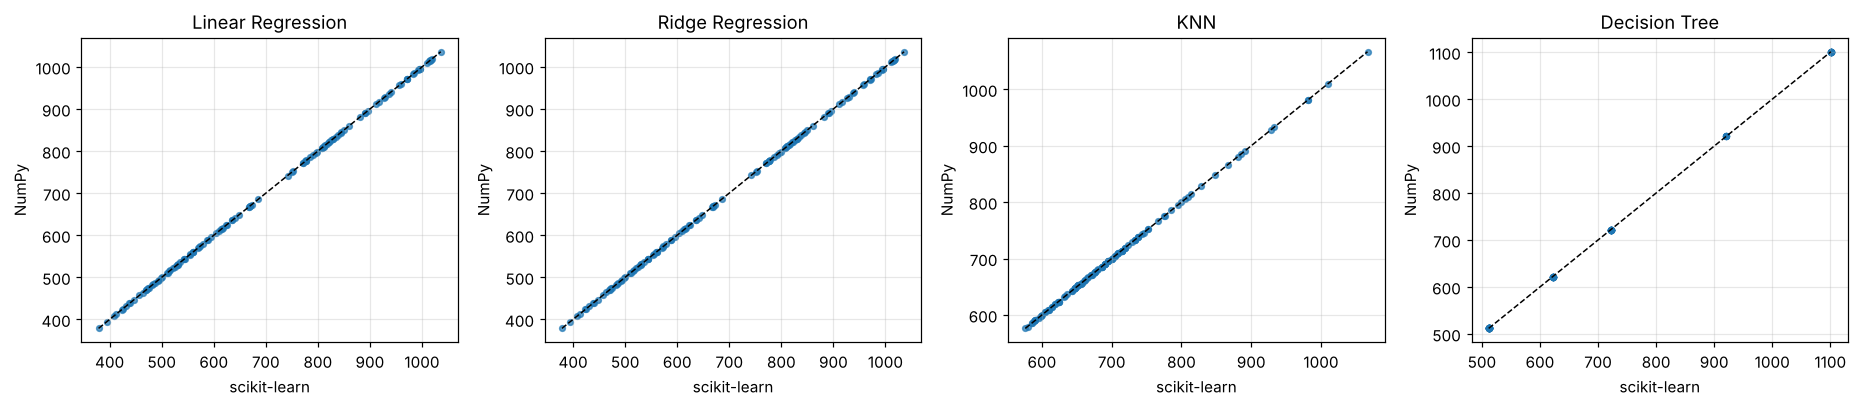

In [37]:
# Visual agreement of the four scratch models with scikit-learn on the test set
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, (name, sc) in zip(ax, scratch_reg.items()):
    a.scatter(reg_store[name]["test_pred"], sc["test_pred"], s=14, alpha=0.7)
    lims = [min(sc["test_pred"].min(), reg_store[name]["test_pred"].min()), max(sc["test_pred"].max(), reg_store[name]["test_pred"].max())]
    a.plot(lims, lims, "k--", lw=1); a.set_title(name); a.set_xlabel("scikit-learn"); a.set_ylabel("NumPy")
plt.tight_layout(); plt.show()

---
## Part E: Gradient Descent
Linear regression can be solved in closed form, but gradient descent is the engine behind logistic regression, SVMs and neural networks. Here we study it on the same regression problem (next-day price). The loss is the mean squared error

$$J(\theta)=\frac1m\sum_i\left(x_i\theta-y_i\right)^2,\qquad \nabla J=\frac{2}{m}X^T(X\theta-y),\qquad \theta\leftarrow\theta-\alpha\nabla J$$

| Variant | Rows used per update | Updates per epoch (610 rows) | Character |
|---|---|---|---|
| **Batch GD** | all rows | 1 | smooth, exact gradient, slow per epoch |
| **Stochastic GD** | 1 random row | 610 | noisy, fast progress, never fully settles |
| **Mini-batch GD** | 32 random rows | 20 | the practical compromise |

The target is standardised here ($y_s=(y-\mu_y)/\sigma_y$) so that the loss is in the same units for every experiment; predictions are converted back to Rs/quintal for the final comparison. The **closed-form (normal equation) solution is the reference optimum** that every run is measured against.

**A property of this dataset worth knowing:** `price_momentum_7` is exactly `modal_price - price_lag_7`, so the design matrix is rank-deficient (one redundant column, smallest eigenvalue about 1e-15). The normal equation copes by using the pseudo-inverse (minimum-norm solution) and gradient descent started from zero converges to that same minimum-norm solution, but along the redundant direction it simply has nothing to move.

In [38]:
# ---- Standardised target and the closed-form optimum --------------------------------------
mu_y, sd_y = yr_train.mean(), yr_train.std()
ys_train, ys_val, ys_test = [(y - mu_y) / sd_y for y in (yr_train, yr_val, yr_test)]

theta_opt = np_linreg_fit(Xr_train_s, ys_train)                       # exact least-squares solution
opt_train_mse = np.mean((add_bias(Xr_train_s) @ theta_opt - ys_train) ** 2)
opt_val_mse   = np.mean((add_bias(Xr_val_s)   @ theta_opt - ys_val)   ** 2)
print(f"Closed-form optimum: train MSE = {opt_train_mse:.5f}, validation MSE = {opt_val_mse:.5f} (standardised units)")

# How hard is the problem for gradient descent? The largest stable learning rate is 1/lambda_max of (X^T X / m)
A_tr = add_bias(Xr_train_s)
eig = np.linalg.eigvalsh(A_tr.T @ A_tr / len(A_tr))
print(f"Eigenvalues of X^T X / m: largest = {eig.max():.2f}, smallest = {eig.min():.2e}, "
      f"condition number = {eig.max() / eig.min():.0f}")
print(f"Numerical rank of the design matrix: {np.linalg.matrix_rank(A_tr)} of {A_tr.shape[1]} columns (bias included)")
print(f"Theory: batch GD diverges when learning rate > 1/lambda_max = {1 / eig.max():.3f}")

# ---- Gradient descent written from scratch (batch / stochastic / mini-batch) --------------
def gd_linear(X, y, method="batch", lr=0.05, epochs=300, batch_size=32, seed=0, X_val=None, y_val=None):
    """
    Gradient descent for linear regression (MSE loss).
    method: 'batch' (all rows), 'sgd' (1 row per update) or 'mini' (batch_size rows per update)
    Returns the final theta and the train / validation MSE after every epoch.
    """
    A = add_bias(X); n = len(A)
    Av = add_bias(X_val) if X_val is not None else None
    theta = np.zeros(A.shape[1])
    rng = np.random.default_rng(seed)
    train_hist, val_hist, diverged = [], [], False
    with np.errstate(all="ignore"):                                   # silence overflow warnings when diverging
        for ep in range(epochs):
            if method == "batch":
                theta = theta - lr * (2 / n) * A.T @ (A @ theta - y)  # one update from the full gradient
            else:
                order = rng.permutation(n)                            # reshuffle every epoch
                bs = 1 if method == "sgd" else batch_size
                for s in range(0, n, bs):
                    idx = order[s:s + bs]
                    Ab = A[idx]
                    theta = theta - lr * (2 / len(idx)) * Ab.T @ (Ab @ theta - y[idx])
            tm = np.mean((A @ theta - y) ** 2)
            if not np.isfinite(tm) or tm > 1e12:                      # blow-up -> stop and mark as diverged
                diverged = True
                train_hist += [np.inf] * (epochs - ep); val_hist += [np.inf] * (epochs - ep)
                break
            train_hist.append(tm)
            if Av is not None:
                val_hist.append(np.mean((Av @ theta - y_val) ** 2))
    return {"theta": theta, "train": np.array(train_hist), "val": np.array(val_hist), "diverged": diverged}

def epochs_to(hist, target):
    """First epoch at which the loss is at or below target (None if never)."""
    hit = np.where(hist <= target)[0]
    return int(hit[0]) + 1 if len(hit) else None

Closed-form optimum: train MSE = 0.07400, validation MSE = 0.01107 (standardised units)
Eigenvalues of X^T X / m: largest = 9.50, smallest = 1.10e-15, condition number = 8641110190243280
Numerical rank of the design matrix: 16 of 17 columns (bias included)
Theory: batch GD diverges when learning rate > 1/lambda_max = 0.105


### E.1 Batch vs Stochastic vs Mini-batch gradient descent

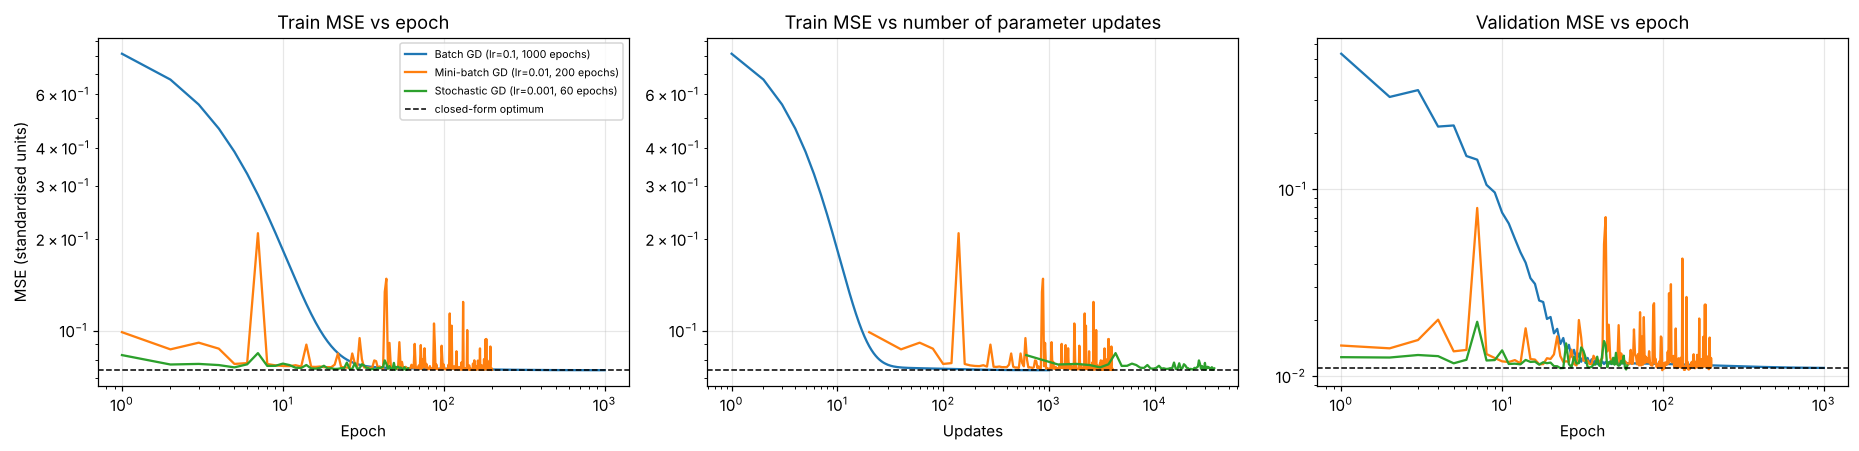

In [39]:
# One setting per variant. The learning rates were picked with the sweep in E.2 (smallest train-loss gap, no test data used)
runs = {
    "Batch GD (lr=0.1, 1000 epochs)":        gd_linear(Xr_train_s, ys_train, "batch", lr=0.1,   epochs=1000, X_val=Xr_val_s, y_val=ys_val),
    "Mini-batch GD (lr=0.01, 200 epochs)":   gd_linear(Xr_train_s, ys_train, "mini",  lr=0.01,  epochs=200,  X_val=Xr_val_s, y_val=ys_val),
    "Stochastic GD (lr=0.001, 60 epochs)":   gd_linear(Xr_train_s, ys_train, "sgd",   lr=0.001, epochs=60,   X_val=Xr_val_s, y_val=ys_val),
}
updates_per_epoch = {"Batch": 1, "Mini-batch": int(np.ceil(len(Xr_train_s) / 32)), "Stochastic": len(Xr_train_s)}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for name, r in runs.items():
    ax[0].plot(np.arange(1, len(r["train"]) + 1), r["train"], label=name)
    ups = updates_per_epoch[name.split()[0]]
    ax[1].plot(np.arange(1, len(r["train"]) + 1) * ups, r["train"], label=name)
    ax[2].plot(np.arange(1, len(r["val"]) + 1), r["val"], label=name)
for a, t in zip(ax, ["Train MSE vs epoch", "Train MSE vs number of parameter updates", "Validation MSE vs epoch"]):
    a.set_xscale("log"); a.set_yscale("log"); a.set_title(t)
ax[0].axhline(opt_train_mse, color="k", ls="--", lw=1, label="closed-form optimum")
ax[1].axhline(opt_train_mse, color="k", ls="--", lw=1)
ax[2].axhline(opt_val_mse, color="k", ls="--", lw=1)
ax[0].set_xlabel("Epoch"); ax[1].set_xlabel("Updates"); ax[2].set_xlabel("Epoch")
ax[0].set_ylabel("MSE (standardised units)"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### E.2 Learning-rate experiments

In [40]:
# Sweep the learning rate for each variant. 'epochs to 1%' = first epoch when train MSE is within 1% of the optimum.
target = opt_train_mse * 1.01
sweeps = {"batch": ([0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5], 1000),
          "mini":  ([0.001, 0.005, 0.01, 0.05, 0.1, 0.2],       150),
          "sgd":   ([0.0005, 0.001, 0.005, 0.01, 0.05, 0.1],    60)}
lr_results, lr_rows = {}, []
for method, (lrs, ep) in sweeps.items():
    for lr in lrs:
        r = gd_linear(Xr_train_s, ys_train, method, lr=lr, epochs=ep, X_val=Xr_val_s, y_val=ys_val)
        lr_results[(method, lr)] = r
        lr_rows.append({"method": method, "learning rate": lr, "epochs run": ep,
                        "final train MSE": r["train"][-1] if not r["diverged"] else np.inf,
                        "gap to optimum": r["train"][-1] - opt_train_mse if not r["diverged"] else np.inf,
                        "epochs to 1% of optimum": epochs_to(r["train"], target) or "not reached",
                        "diverged": r["diverged"]})
lr_table = pd.DataFrame(lr_rows)
lr_table["final train MSE"] = lr_table["final train MSE"].astype(float)
lr_table["gap to optimum"]  = lr_table["gap to optimum"].astype(float)
lr_table.round(5)

,method,learning rate,epochs run,final train MSE,gap to optimum,epochs to 1% of optimum,diverged
0,batch,0.0010,1000,0.07761,0.00361,not reached,False
1,batch,0.0050,1000,0.07523,0.00123,not reached,False
2,batch,0.0100,1000,0.07480,0.00080,not reached,False
3,batch,0.0500,1000,0.07406,0.00006,221,False
4,batch,0.1000,1000,0.07400,0.00000,111,False
5,batch,0.2000,1000,inf,inf,not reached,True
6,batch,0.5000,1000,inf,inf,not reached,True
7,mini,0.0010,150,0.07556,0.00156,not reached,False
8,mini,0.0050,150,0.07460,0.00061,123,False
9,mini,0.0100,150,0.07447,0.00048,71,False


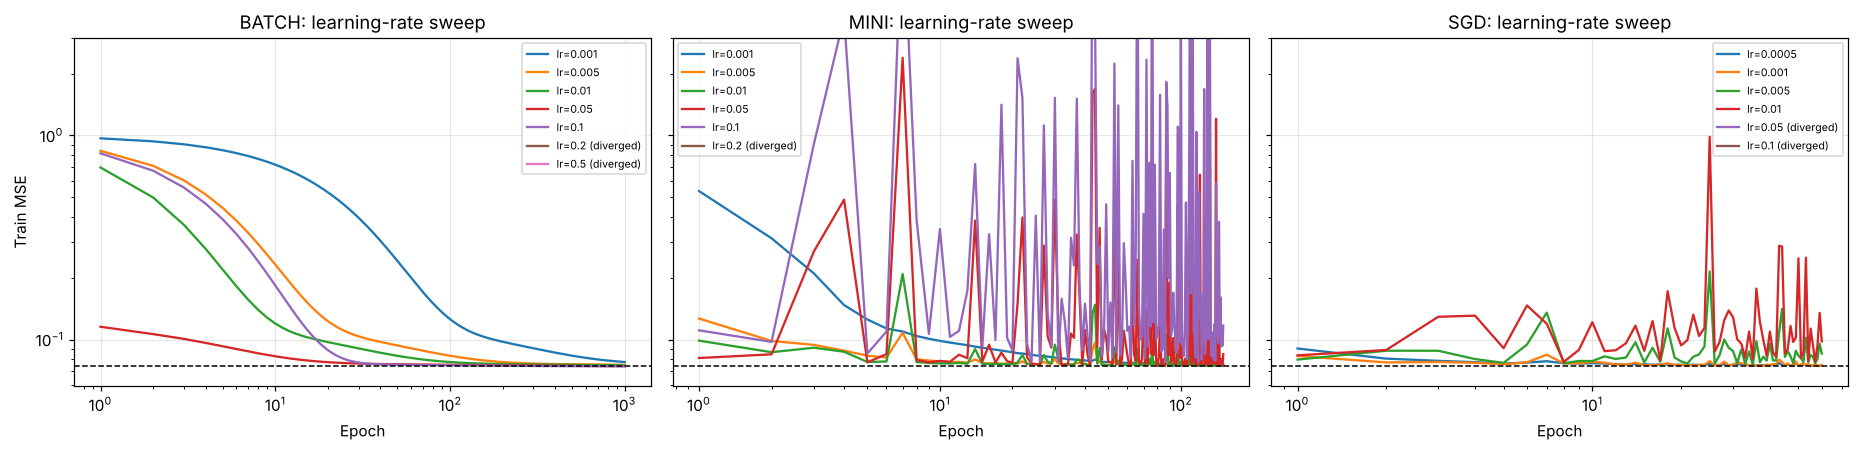

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for a, (method, (lrs, ep)) in zip(ax, sweeps.items()):
    for lr in lrs:
        h = lr_results[(method, lr)]["train"]
        a.plot(np.arange(1, len(h) + 1), np.where(np.isfinite(h), h, np.nan), label=f"lr={lr}" + (" (diverged)" if lr_results[(method, lr)]["diverged"] else ""))
    a.axhline(opt_train_mse, color="k", ls="--", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_ylim(opt_train_mse * 0.8, 3)
    a.set_title(f"{method.upper()}: learning-rate sweep"); a.set_xlabel("Epoch"); a.legend(fontsize=7)
ax[0].set_ylabel("Train MSE")
plt.tight_layout(); plt.show()

### E.3 Learning curves

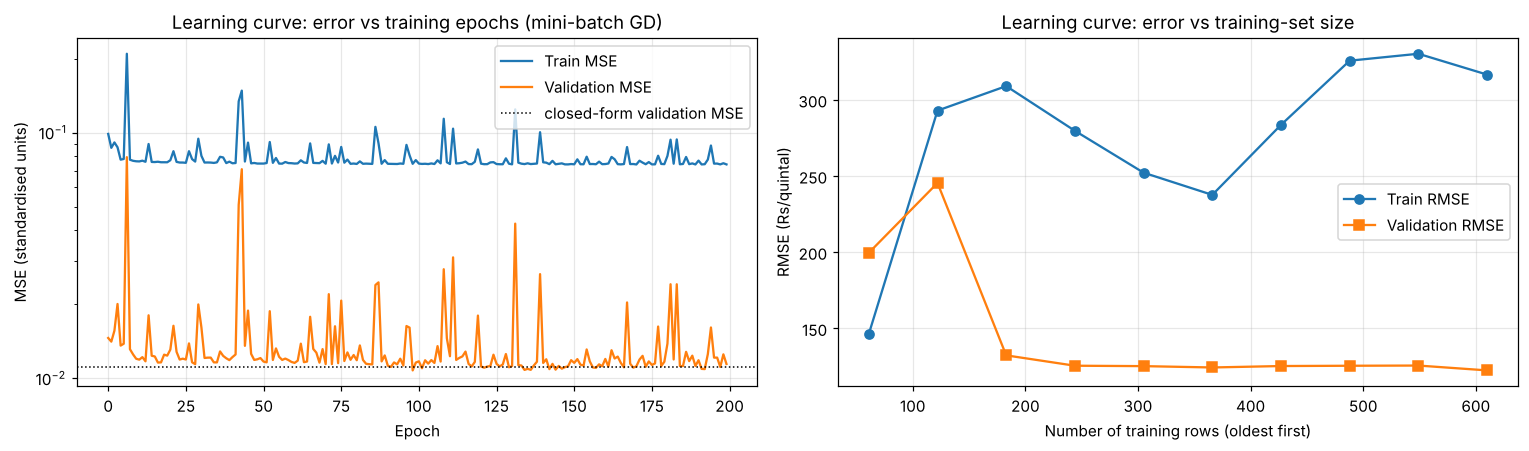

 training rows  train RMSE  validation RMSE
            61       146.4            199.7
           122       293.0            245.5
           183       309.1            132.3
           244       279.7            125.5
           305       252.2            125.3
           366       237.7            124.4
           427       283.6            125.3
           488       325.7            125.5
           549       330.3            125.7
           610       316.6            122.5


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))

# (a) Loss curves: training vs validation error per epoch for mini-batch GD
r = runs["Mini-batch GD (lr=0.01, 200 epochs)"]
ax[0].plot(r["train"], label="Train MSE"); ax[0].plot(r["val"], label="Validation MSE")
ax[0].axhline(opt_val_mse, color="k", ls=":", lw=1, label="closed-form validation MSE")
ax[0].set_yscale("log"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE (standardised units)")
ax[0].set_title("Learning curve: error vs training epochs (mini-batch GD)"); ax[0].legend()

# (b) Learning curve vs amount of training data (chronological prefixes of the training set, closed-form fit)
sizes = np.linspace(0.1, 1.0, 10)
tr_rmse, va_rmse, n_used = [], [], []
for f in sizes:
    m_ = int(f * len(Xr_train)); Xs, ysub = Xr_train[:m_], yr_train[:m_]
    mu, sd = np_fit_scaler(Xs); sd = np.where(sd == 0, 1, sd)           # scaler re-fitted on the subset
    th = np_linreg_fit(np_transform(Xs, mu, sd), ysub)
    tr_rmse.append(np_rmse(ysub, np_linreg_predict(np_transform(Xs, mu, sd), th)))
    va_rmse.append(np_rmse(yr_val, np_linreg_predict(np_transform(Xr_val, mu, sd), th)))
    n_used.append(m_)
ax[1].plot(n_used, tr_rmse, "o-", label="Train RMSE"); ax[1].plot(n_used, va_rmse, "s-", label="Validation RMSE")
ax[1].set_xlabel("Number of training rows (oldest first)"); ax[1].set_ylabel("RMSE (Rs/quintal)")
ax[1].set_title("Learning curve: error vs training-set size"); ax[1].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame({"training rows": n_used, "train RMSE": np.round(tr_rmse, 1), "validation RMSE": np.round(va_rmse, 1)}).to_string(index=False))

### E.4 Convergence analysis

In [43]:
rows = []
for name, r in runs.items():
    tail = r["train"][-10:]                                                # last 10 epochs
    ep1 = epochs_to(r["train"], target)
    rows.append({"method": name,
                 "epochs to 1% of optimum": ep1 or "not reached",
                 "updates to 1% of optimum": (ep1 * updates_per_epoch[name.split()[0]]) if ep1 else "not reached",
                 "final train MSE": r["train"][-1],
                 "gap to optimum": r["train"][-1] - opt_train_mse,
                 "wobble (std of last 10 epochs)": tail.std(),
                 "||theta - theta_opt||": np.linalg.norm(r["theta"] - theta_opt),
                 "validation MSE": r["val"][-1]})
conv_table = pd.DataFrame(rows).set_index("method")
conv_table.round(5)

,epochs to 1% of optimum,updates to 1% of optimum,final train MSE,gap to optimum,wobble (std of last 10 epochs),||theta - theta_opt||,validation MSE
method,,,,,,,
"Batch GD (lr=0.1, 1000 epochs)",111,111,0.07400,0.00000,0.00000,0.02854,0.01108
"Mini-batch GD (lr=0.01, 200 epochs)",71,1420,0.07422,0.00022,0.00419,0.09431,0.01144
"Stochastic GD (lr=0.001, 60 epochs)",21,12810,0.07506,0.00106,0.00062,0.09639,0.01141


### E.5 Feature-scaling comparison

Closed-form reference: train MSE 0.07400, test RMSE 106.56 Rs


,best stable lr,final train MSE,gap to optimum,epochs to 1% of optimum,test RMSE (Rs)
scaling,,,,,
Raw features (no scaling),1e-08,0.18138,0.10738,not reached,485.59580
"Min-max scaling [0, 1]",0.3,0.07470,0.00070,951,106.36920
Standardisation (z-score),0.1,0.07400,0.00000,111,106.45173


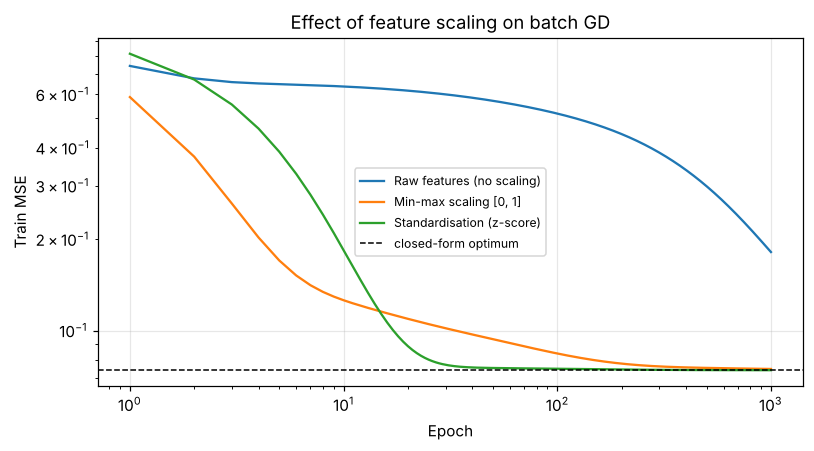

In [44]:
# Same batch GD, same 1000 epochs, three ways of preparing the features. For each, the best stable learning rate
# from a small grid is used, so the comparison is fair. Target is the standardised price in all cases.
mn, mx = Xr_train.min(axis=0), Xr_train.max(axis=0)
variants = {
    "Raw features (no scaling)":   (Xr_train, Xr_val, Xr_test, [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]),
    "Min-max scaling [0, 1]":      ((Xr_train - mn) / (mx - mn), (Xr_val - mn) / (mx - mn), (Xr_test - mn) / (mx - mn), [0.01, 0.05, 0.1, 0.3, 0.6]),
    "Standardisation (z-score)":   (Xr_train_s, Xr_val_s, Xr_test_s, [0.001, 0.01, 0.05, 0.1, 0.2]),
}
scale_rows, scale_curves = [], {}
for name, (Xa, Xv, Xt, grid) in variants.items():
    best = None
    for lr in grid:
        r = gd_linear(Xa, ys_train, "batch", lr=lr, epochs=1000, X_val=Xv, y_val=ys_val)
        if not r["diverged"] and (best is None or r["train"][-1] < best[1]["train"][-1]):
            best = (lr, r)
    lr, r = best
    pred_test = (add_bias(Xt) @ r["theta"]) * sd_y + mu_y                  # back to Rs/quintal
    scale_curves[name] = r["train"]
    scale_rows.append({"scaling": name, "best stable lr": f"{lr:g}", "final train MSE": r["train"][-1],
                       "gap to optimum": r["train"][-1] - opt_train_mse,
                       "epochs to 1% of optimum": epochs_to(r["train"], target) or "not reached",
                       "test RMSE (Rs)": np_rmse(yr_test, pred_test)})
scale_table = pd.DataFrame(scale_rows).set_index("scaling")
print(f"Closed-form reference: train MSE {opt_train_mse:.5f}, test RMSE "
      f"{np_rmse(yr_test, np_linreg_predict(Xr_test_s, np_linreg_fit(Xr_train_s, yr_train))):.2f} Rs")
display(scale_table.round(5))

plt.figure(figsize=(7.5, 4.2))
for name, h in scale_curves.items():
    plt.plot(np.arange(1, len(h) + 1), h, label=name)
plt.axhline(opt_train_mse, color="k", ls="--", lw=1, label="closed-form optimum")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Train MSE"); plt.title("Effect of feature scaling on batch GD")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### E.6 Comparison with scikit-learn `SGDRegressor`

In [45]:
# scikit-learn's squared_error loss is 0.5*e^2 (gradient e) while ours is e^2 (gradient 2e), so the equivalent
# constant learning rates differ by a factor of 2: eta0 = 0.002 in sklearn  <->  lr = 0.001 in our SGD.
sk_sgd = SGDRegressor(loss="squared_error", penalty=None, learning_rate="constant", eta0=0.002,
                      max_iter=60, tol=None, shuffle=True, random_state=RS)
sk_sgd.fit(Xr_train_s, ys_train)
sk_sgd_inv = SGDRegressor(loss="squared_error", penalty=None, learning_rate="invscaling", eta0=0.01,
                          max_iter=60, tol=None, random_state=RS).fit(Xr_train_s, ys_train)

theta_sgd = runs["Stochastic GD (lr=0.001, 60 epochs)"]["theta"]
theta_bgd = runs["Batch GD (lr=0.1, 1000 epochs)"]["theta"]
theta_mgd = runs["Mini-batch GD (lr=0.01, 200 epochs)"]["theta"]

def to_rs(pred_s):                       # standardised prediction -> Rs/quintal
    return pred_s * sd_y + mu_y

cands = {
    "Closed form (normal equation)":      to_rs(add_bias(Xr_test_s) @ theta_opt),
    "NumPy batch GD":                     to_rs(add_bias(Xr_test_s) @ theta_bgd),
    "NumPy mini-batch GD":                to_rs(add_bias(Xr_test_s) @ theta_mgd),
    "NumPy SGD (lr=0.001)":               to_rs(add_bias(Xr_test_s) @ theta_sgd),
    "sklearn SGDRegressor (constant lr)": to_rs(sk_sgd.predict(Xr_test_s)),
    "sklearn SGDRegressor (invscaling)":  to_rs(sk_sgd_inv.predict(Xr_test_s)),
}
rows = []
for name, p in cands.items():
    s = reg_scores(yr_test, p)
    rows.append({"model": name, **s, "max |pred diff| vs closed form (Rs)": np.abs(p - cands["Closed form (normal equation)"]).max()})
gd_table = pd.DataFrame(rows).set_index("model")
display(gd_table.round(3))

coef_cmp = pd.DataFrame({"feature": ["(intercept)"] + REG_FEATURES,
                         "closed form": theta_opt, "NumPy SGD": theta_sgd,
                         "sklearn SGD": np.r_[sk_sgd.intercept_, sk_sgd.coef_]})
print("Coefficient correlation with the closed-form solution:",
      "NumPy SGD = %.3f," % np.corrcoef(coef_cmp["closed form"], coef_cmp["NumPy SGD"])[0, 1],
      "sklearn SGD = %.3f" % np.corrcoef(coef_cmp["closed form"], coef_cmp["sklearn SGD"])[0, 1])
coef_cmp.round(3)

,MAE,MSE,RMSE,R2,max |pred diff| vs closed form (Rs)
model,,,,,
Closed form (normal equation),77.128,11355.355,106.562,0.729,0.000
NumPy batch GD,76.960,11331.971,106.452,0.729,3.256
NumPy mini-batch GD,77.074,11288.544,106.248,0.730,29.787
NumPy SGD (lr=0.001),76.975,11108.595,105.397,0.735,34.459
sklearn SGDRegressor (constant lr),78.639,11619.286,107.793,0.722,27.101
sklearn SGDRegressor (invscaling),78.465,11640.624,107.892,0.722,31.163


Coefficient correlation with the closed-form solution: NumPy SGD = 0.983, sklearn SGD = 0.983


,feature,closed form,NumPy SGD,sklearn SGD
0,(intercept),-0.000,-0.002,-0.002
1,modal_price_rs_per_qtl,0.296,0.257,0.260
2,price_prev_obs,0.193,0.180,0.182
3,price_lag_3,0.078,0.068,0.068
4,price_lag_7,0.214,0.186,0.179
5,rolling_mean_7,0.131,0.101,0.100
6,rolling_std_7,-0.037,-0.041,-0.039
7,rolling_min_7,-0.049,0.008,0.003
8,rolling_max_7,-0.047,-0.002,-0.004
9,price_momentum_7,0.149,0.131,0.150


---
## Part F: Final Analysis
All models are now compared on the **same held-out test period**. Because test results are only one six-month window, a model is *selected* with the validation set (and cross-validation for classifiers) and the test set is used to report how that choice performs, not to pick it.

### F.1 All classification models

In [46]:
# Collect every classifier (sklearn, from scratch, and the Foundation logistic models) in one table
all_clf = {}
for n, d in clf_store.items():
    all_clf[f"{n} [sklearn]"] = (d["val_score"], d["test_score"], d["test_label"])
for n, d in scratch_clf.items():
    all_clf[f"{n} [NumPy]"] = (d["val_score"], d["test_score"], d["test_label"])
all_clf["Logistic Regression [sklearn]"] = (proba_sk["Validation"], proba_sk["Test"], label_sk["Test"])
all_clf["Logistic Regression [NumPy]"]   = (proba_np["Validation"], proba_np["Test"], label_np["Test"])

rows = []
for name, (vs, ts, tl) in all_clf.items():
    base = name.split(" [")[0]
    rows.append({"model": name, "CV ROC-AUC (train+val)": cv_auc.get(base if base != "Logistic Regression" else "Logistic Regression (Foundation)", np.nan) if "[sklearn]" in name else np.nan,
                 "Validation AUC": roc_auc_score(yc_val, vs), **clf_scores(yc_test, tl, ts)})
clf_all = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
display(clf_all.round(3))

# Majority-class reference and the picks
print(f"Reference: always predicting 'no surge' gives test accuracy {1 - yc_test.mean():.3f}, F1 0, ROC-AUC 0.5")
sk_only = clf_all[clf_all.index.str.contains(r"\[sklearn\]")]
print("Best by cross-validated AUC (sklearn models):", sk_only["CV ROC-AUC (train+val)"].idxmax())
print("Best by validation AUC (all)                 :", clf_all["Validation AUC"].idxmax())
print("Best by test ROC-AUC                          :", clf_all["ROC-AUC"].idxmax())
print("Best by test F1                               :", clf_all["F1"].idxmax())

,CV ROC-AUC (train+val),Validation AUC,Accuracy,Precision,Recall,F1,ROC-AUC
model,,,,,,,
Logistic Regression [sklearn],0.588,0.616,0.627,0.364,0.195,0.254,0.636
Logistic Regression [NumPy],NaN,0.616,0.627,0.364,0.195,0.254,0.636
SVM (linear kernel) [NumPy],NaN,0.627,0.643,0.333,0.098,0.151,0.555
SVM (linear kernel) [sklearn],0.591,0.627,0.643,0.333,0.098,0.151,0.555
SVM (RBF kernel) [sklearn],0.630,0.716,0.548,0.289,0.268,0.278,0.476
Gaussian Naive Bayes [NumPy],NaN,0.608,0.310,0.315,0.951,0.473,0.443
Gaussian Naive Bayes [sklearn],0.564,0.608,0.310,0.315,0.951,0.473,0.443
KNN [NumPy],NaN,0.658,0.667,0.000,0.000,0.000,0.432
KNN [sklearn],0.610,0.658,0.667,0.000,0.000,0.000,0.432


Reference: always predicting 'no surge' gives test accuracy 0.675, F1 0, ROC-AUC 0.5
Best by cross-validated AUC (sklearn models): SVM (RBF kernel) [sklearn]
Best by validation AUC (all)                 : SVM (RBF kernel) [sklearn]
Best by test ROC-AUC                          : Logistic Regression [sklearn]
Best by test F1                               : Gaussian Naive Bayes [NumPy]


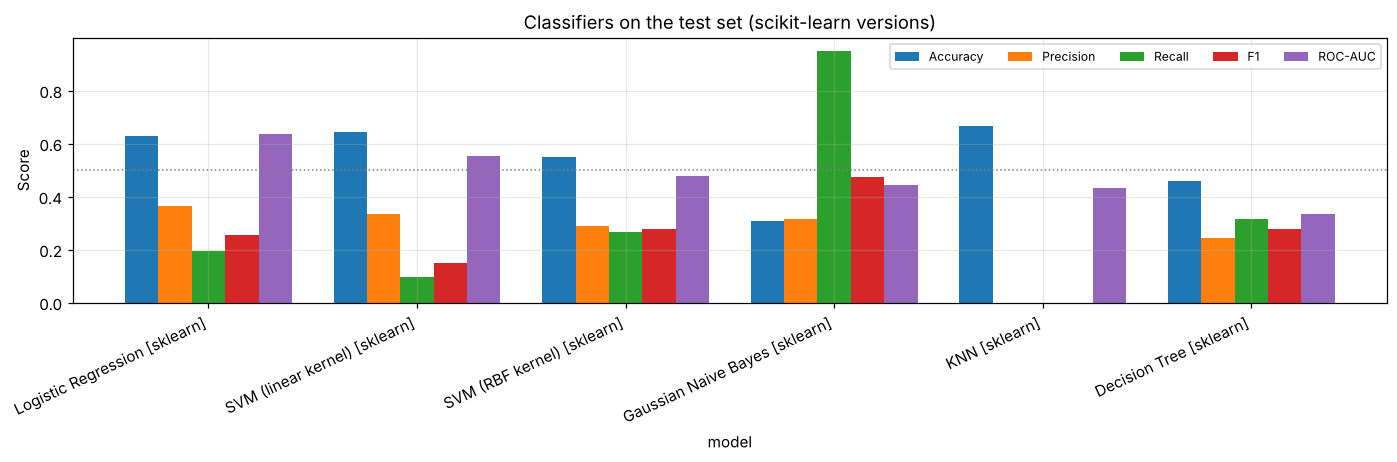

In [47]:
# Visual comparison of the scikit-learn classifiers on the key metrics
plot_df = clf_all[clf_all.index.str.contains(r"\[sklearn\]")][["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = plot_df.plot(kind="bar", figsize=(13, 4.3), width=0.8)
ax.axhline(0.5, color="grey", ls=":", lw=1); ax.set_ylabel("Score"); ax.set_title("Classifiers on the test set (scikit-learn versions)")
plt.xticks(rotation=25, ha="right"); plt.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

### F.2 All regression models

In [48]:
all_reg = {"Naive (tomorrow = today)": (None, naive_test)}
for n, d in reg_store.items():
    all_reg[f"{n} [sklearn]"] = (d["val_pred"], d["test_pred"])
for n, d in scratch_reg.items():
    all_reg[f"{n} [NumPy]"] = (d["val_pred"], d["test_pred"])
all_reg["Batch GD [NumPy]"]       = (to_rs(add_bias(Xr_val_s) @ theta_bgd), cands["NumPy batch GD"])
all_reg["Mini-batch GD [NumPy]"]  = (to_rs(add_bias(Xr_val_s) @ theta_mgd), cands["NumPy mini-batch GD"])
all_reg["SGD [NumPy]"]            = (to_rs(add_bias(Xr_val_s) @ theta_sgd), cands["NumPy SGD (lr=0.001)"])
all_reg["SGDRegressor [sklearn]"] = (to_rs(sk_sgd.predict(Xr_val_s)), cands["sklearn SGDRegressor (constant lr)"])

rows = []
for name, (vp, tp) in all_reg.items():
    rows.append({"model": name,
                 "Validation RMSE": reg_scores(yr_val, vp)["RMSE"] if vp is not None else reg_scores(yr_val, val["modal_price_rs_per_qtl"].values)["RMSE"],
                 **reg_scores(yr_test, tp)})
reg_all = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
display(reg_all.round(3))
print("Best by validation RMSE:", reg_all["Validation RMSE"].idxmin())
print("Best by test RMSE      :", reg_all["RMSE"].idxmin())
print("Best by test MAE       :", reg_all["MAE"].idxmin())

,Validation RMSE,MAE,MSE,RMSE,R2
model,,,,,
Lasso Regression [sklearn],116.891,75.128,10789.913,103.875,0.742
SGD [NumPy],124.344,76.975,11108.595,105.397,0.735
Mini-batch GD [NumPy],124.498,77.074,11288.544,106.248,0.730
Batch GD [NumPy],122.532,76.960,11331.971,106.452,0.729
Ridge Regression [NumPy],122.499,77.109,11351.746,106.545,0.729
Ridge Regression [sklearn],122.499,77.109,11351.746,106.545,0.729
Linear Regression [NumPy],122.478,77.128,11355.355,106.562,0.729
Linear Regression [sklearn],122.478,77.128,11355.355,106.562,0.729
SGDRegressor [sklearn],127.008,78.639,11619.286,107.793,0.722


Best by validation RMSE: Lasso Regression [sklearn]
Best by test RMSE      : Lasso Regression [sklearn]
Best by test MAE       : Naive (tomorrow = today)


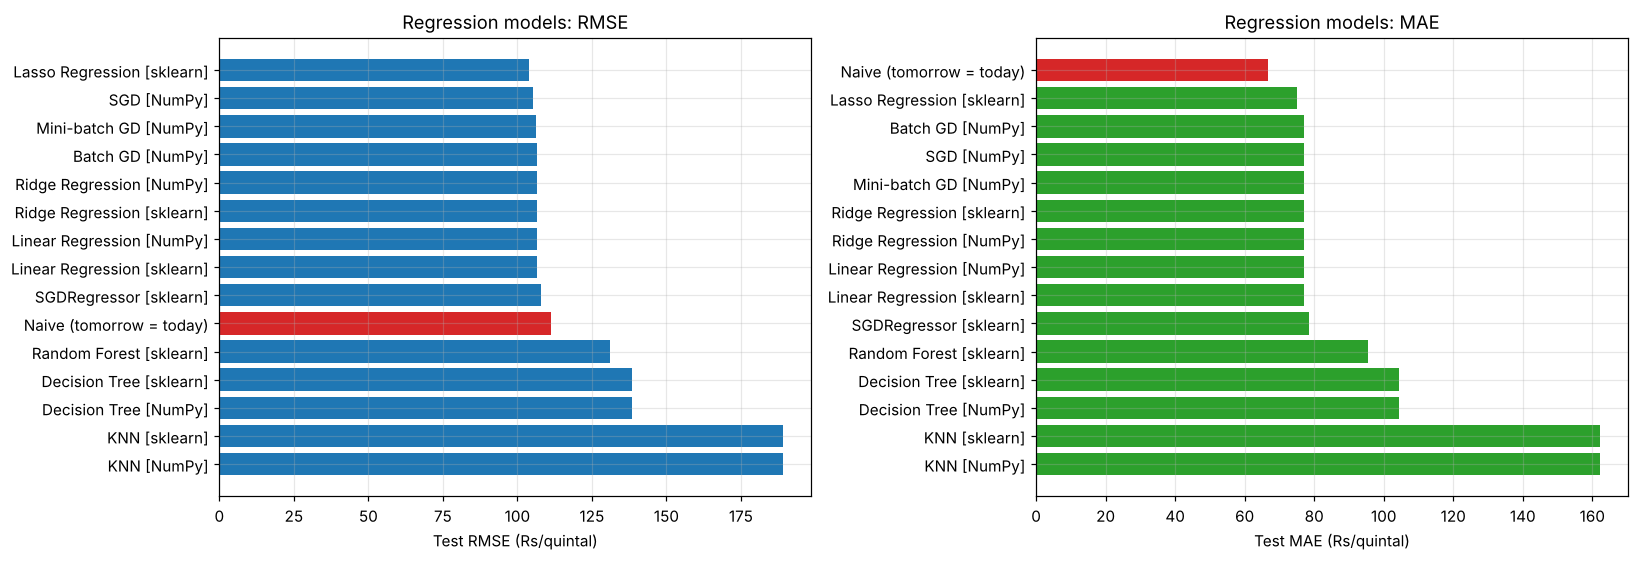

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
d1 = reg_all.sort_values("RMSE")
ax[0].barh(d1.index, d1["RMSE"], color=["tab:red" if i.startswith("Naive") else "tab:blue" for i in d1.index])
ax[0].invert_yaxis(); ax[0].set_xlabel("Test RMSE (Rs/quintal)"); ax[0].set_title("Regression models: RMSE")
d2 = reg_all.sort_values("MAE")
ax[1].barh(d2.index, d2["MAE"], color=["tab:red" if i.startswith("Naive") else "tab:green" for i in d2.index])
ax[1].invert_yaxis(); ax[1].set_xlabel("Test MAE (Rs/quintal)"); ax[1].set_title("Regression models: MAE")
plt.tight_layout(); plt.show()

### F.3 Which inflation indicators matter?

In [50]:
# ---- (1) Classification: permutation importance on the held-out data (validation + test) ---------
# Shuffling one feature at a time and measuring how much the ROC-AUC drops shows how much the model relies on it.
Xc_hold = np.vstack([Xc_val_s, Xc_test_s]); yc_hold = np.r_[yc_val, yc_test]
best_clf_name = max(clf_store, key=lambda n: clf_store[n]["val_auc"])
print("Best sklearn classifier by validation AUC:", best_clf_name)
pi_clf = permutation_importance(clf_store[best_clf_name]["model"], Xc_hold, yc_hold, scoring="roc_auc",
                                n_repeats=50, random_state=RS)
pi_log = permutation_importance(sk_log, Xc_hold, yc_hold, scoring="roc_auc", n_repeats=50, random_state=RS)

# ---- (2) Direct relationship of each feature with the 7-day price change (Spearman rank correlation) ----
ret7 = df["target_price_t_plus_7"] / df["modal_price_rs_per_qtl"] - 1
spearman = df[CLF_FEATURES].corrwith(ret7, method="spearman")

ind = pd.DataFrame({"permutation importance (best classifier)": pi_clf.importances_mean,
                    "permutation importance (logistic)": pi_log.importances_mean,
                    "logistic coefficient": sk_log.coef_[0],
                    "Spearman corr. with 7-day return": spearman.values,
                    "decision-tree importance": clf_store["Decision Tree"]["model"].feature_importances_},
                   index=CLF_FEATURES)
ind["indicator group"] = ["Price level vs trend", "Volatility", "Momentum", "Short-term change", "Volatility",
                          "Volatility", "Arrivals (supply)", "Arrivals (supply)", "Season", "Season"]
ind.sort_values("permutation importance (logistic)", ascending=False).round(4)

Best sklearn classifier by validation AUC: SVM (RBF kernel)


,permutation importance (best classifier),permutation importance (logistic),logistic coefficient,Spearman corr. with 7-day return,decision-tree importance,indicator group
dev_mean7,0.0707,0.1111,-0.4156,-0.1248,0.1811,Price level vs trend
is_monsoon_season,0.0763,0.0621,-0.2192,-0.1234,0.2059,Season
range7_pct,0.0043,0.0255,0.4454,0.0467,0.1906,Volatility
cv7,0.0138,0.0229,-0.3031,0.0513,0.0000,Volatility
chg1_pct,0.0047,0.0141,-0.0627,-0.1722,0.0000,Short-term change
arr_dev,0.0238,0.0081,-0.1347,-0.0812,0.1496,Arrivals (supply)
spread_pct,-0.0170,0.0038,0.2462,0.0537,0.0506,Volatility
arr_chg,0.0002,0.0029,-0.3090,-0.0746,0.0000,Arrivals (supply)
month,-0.0257,-0.0111,-0.1838,-0.0656,0.2221,Season
mom7_pct,-0.0313,-0.0482,0.5260,-0.0640,0.0000,Momentum


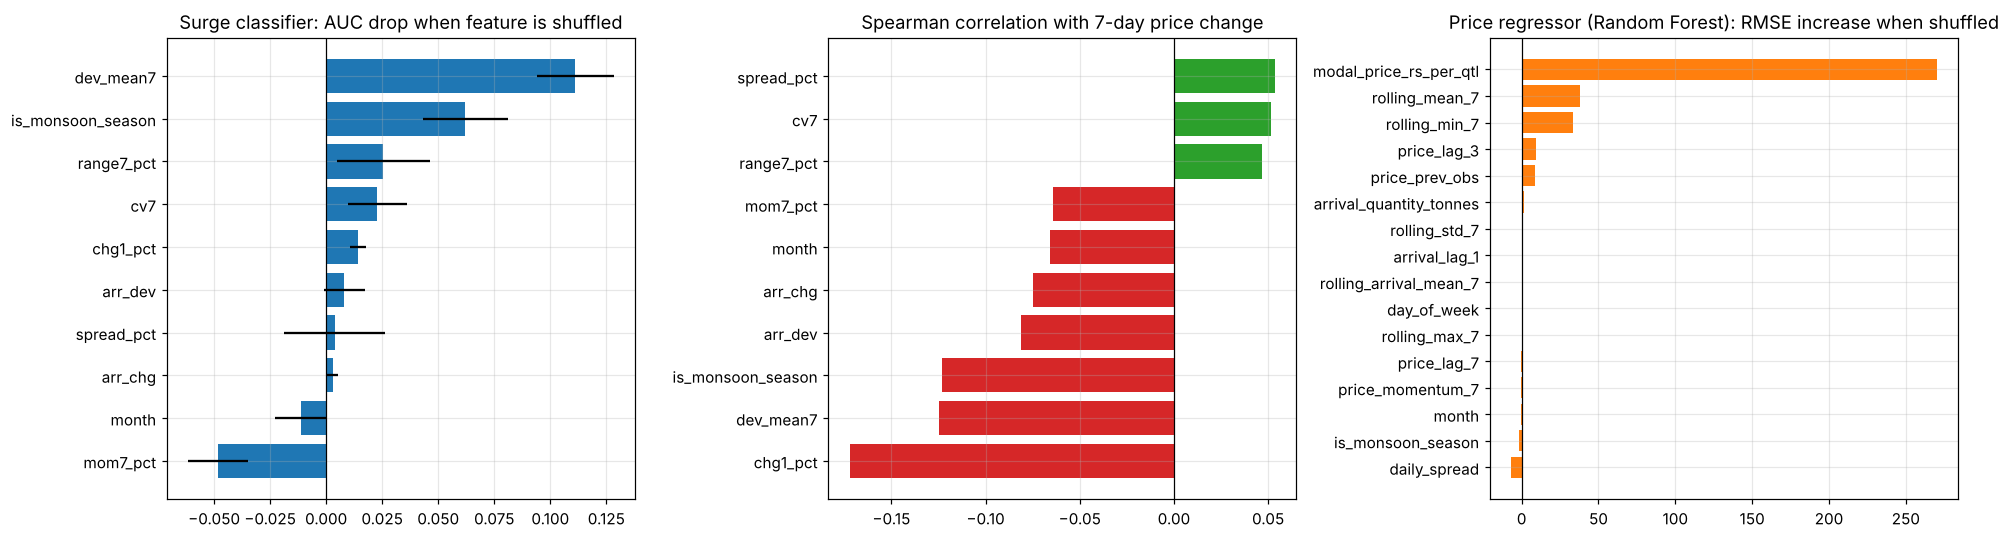

,"RF permutation importance (RMSE increase, Rs)","Linear permutation importance (RMSE increase, Rs)",Random Forest impurity importance,Ridge coefficient
modal_price_rs_per_qtl,270.089,30.370,0.763,342.762
rolling_mean_7,37.777,5.700,0.018,150.439
rolling_min_7,33.730,2.471,0.003,-55.151
price_lag_3,9.451,1.110,0.009,91.105
price_prev_obs,8.553,13.614,0.059,224.369
arrival_quantity_tonnes,1.402,0.792,0.004,-16.687
rolling_std_7,1.097,0.388,0.004,-42.847
arrival_lag_1,0.813,0.011,0.004,0.177
rolling_arrival_mean_7,0.201,2.910,0.006,-30.918
day_of_week,0.062,-0.212,0.003,-10.349


In [51]:
# ---- (3) Regression: which inputs drive the next-day price forecast? -----------------------------
Xr_hold = np.vstack([Xr_val_s, Xr_test_s]); yr_hold = np.r_[yr_val, yr_test]
pi_rf = permutation_importance(reg_store["Random Forest"]["model"], Xr_hold, yr_hold,
                               scoring="neg_root_mean_squared_error", n_repeats=30, random_state=RS)
pi_lr = permutation_importance(reg_store["Linear Regression"]["model"], Xr_hold, yr_hold,
                               scoring="neg_root_mean_squared_error", n_repeats=30, random_state=RS)
reg_imp = pd.DataFrame({"RF permutation importance (RMSE increase, Rs)": pi_rf.importances_mean,
                        "Linear permutation importance (RMSE increase, Rs)": pi_lr.importances_mean,
                        "Random Forest impurity importance": reg_store["Random Forest"]["model"].feature_importances_,
                        "Ridge coefficient": reg_store["Ridge Regression"]["model"].coef_},
                       index=REG_FEATURES).sort_values("RF permutation importance (RMSE increase, Rs)", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
c = ind.sort_values("permutation importance (logistic)")
ax[0].barh(c.index, c["permutation importance (logistic)"], xerr=pi_log.importances_std[[CLF_FEATURES.index(i) for i in c.index]], color="tab:blue")
ax[0].set_title("Surge classifier: AUC drop when feature is shuffled"); ax[0].axvline(0, color="k", lw=0.8)
c = ind.sort_values("Spearman corr. with 7-day return")
ax[1].barh(c.index, c["Spearman corr. with 7-day return"], color=["tab:green" if v > 0 else "tab:red" for v in c["Spearman corr. with 7-day return"]])
ax[1].set_title("Spearman correlation with 7-day price change"); ax[1].axvline(0, color="k", lw=0.8)
c = reg_imp.sort_values("RF permutation importance (RMSE increase, Rs)")
ax[2].barh(c.index, c["RF permutation importance (RMSE increase, Rs)"], color="tab:orange")
ax[2].set_title("Price regressor (Random Forest): RMSE increase when shuffled"); ax[2].axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()
reg_imp.round(3)

### F.4 Best-performing algorithms
**Classification (7-day surge alert).** No algorithm is a dependable alert system on this data, but they differ in *how* they fail.

| Criterion | Winner | Test result |
|---|---|---|
| Best validation AUC and best cross-validated AUC | SVM (RBF) | validation 0.716, CV 0.630 ± 0.096, **but test AUC 0.476 (no better than chance)** |
| Best test ROC-AUC | Logistic Regression | 0.636 (validation 0.616, CV 0.588) |
| Best test F1 | Gaussian Naive Bayes | F1 0.473, but only because it flags almost every day (recall 0.95, accuracy 0.31) |
| Best test accuracy | KNN (k = 51) | 0.667, but it never predicts a surge (recall 0), so it does not even reach the 0.675 of "always no surge" |

The most trustworthy choice is **Logistic Regression**: together with the linear SVM it is the only model whose AUC stays above 0.5 in cross-validation, on the validation period *and* on the test period, and it has the higher test AUC of the two (0.636 vs 0.555). It is also the simplest model and gives calibrated-style probabilities, and the more flexible ones (RBF SVM, tree, KNN) learned patterns of the 2016-2018 training years that did not carry over to July-December 2018.

**Regression (next-price forecast).** **Lasso Regression** is best on both validation (RMSE 116.9) and test (RMSE 103.9, MAE 75.1, R² 0.742). Linear, Ridge and batch gradient descent are practically tied just behind (RMSE about 106.5), and mini-batch / stochastic GD land in the same range when the learning rate is chosen well. The tree-based models (Decision Tree 138.4, Random Forest 131.1) and KNN (189.1) are clearly worse. The naive "tomorrow = today" rule still has the **lowest MAE (66.7)**, so none of the models is a clear improvement on persistence: they trim the large errors (lower RMSE) but add small errors on the many days when the price does not move.

### F.5 Important inflation indicators
* **Price level and recent price history dominate the price forecast.** For the Random Forest, shuffling today's modal price raises the RMSE by about Rs 270, the 7-day average and 7-day minimum by about Rs 34-38, while every arrival-based feature changes the RMSE by less than Rs 2. In plain words: next week's tomato price is mostly this week's price. (Several price features are strongly correlated, and `price_momentum_7` is exactly `modal_price - price_lag_7`, so importance is shared among them; read the ranking as "price history as a group", not as exact individual rankings.)
* **Mean reversion is the main signal for surges.** The features most related to the 7-day price change are the one-step change (Spearman correlation about -0.17) and the price relative to its 7-day mean (about -0.13): after a sharp jump or a price above its weekly average, the price tends to fall back rather than rise further. In the logistic model `dev_mean7` is also the most important feature (AUC drop about 0.11 when shuffled).
* **Season matters.** The monsoon flag has a negative relation with surges (correlation about -0.12; AUC drop about 0.06) and `month`/`is_monsoon_season` are among the top features of the decision tree. The month effect is strong in training but is exactly the kind of pattern that can change between years.
* **Volatility features** (`cv7`, `range7_pct`, `spread_pct`) contribute modestly and with mixed signs: a wide 7-day range and a wide daily spread raise the surge probability (positive logistic coefficients), while the coefficient-of-variation feature `cv7` has a negative one, which is another sign that these correlated features share the same information.
* **Arrivals (supply)** are weak in this table: `arr_dev` has some effect (AUC drop about 0.01-0.02) but, for the price regression, arrival features are almost irrelevant. This is surprising economically (supply drives mandi prices), and probably reflects that the price already reacts to arrivals at the same moment, so arrivals add little *beyond* the current price.
* **Momentum is not reliable out of sample:** `mom7_pct` has a positive logistic coefficient but shuffling it slightly *improves* held-out AUC (-0.05), i.e. the training-period momentum effect reverses in 2018.

### F.6 Limitations and possible improvements
**Limitations**
1. **Small, single-market data:** 866 usable rows of one commodity in one mandi (Pune tomato, 2016-2018). Test AUCs rest on only 41 surge days, so differences of a few hundredths between models are within noise.
2. **Regime shift:** the mean price falls from about Rs 1,392 (train) to about Rs 655-684 (validation/test). Validation (Feb-Jul 2018) and test (Jul-Dec 2018) are different seasons, so a model that wins on validation can still fail on test (the RBF SVM did exactly this).
3. **Weak, partly circular features:** most features are transformations of the same price series, `price_momentum_7` is an exact combination of two other columns (rank-deficient design matrix), and the data has no weather, rainfall, fuel, festival or transport information, which are the real drivers of tomato price spikes.
4. **Target definition:** "t+1" is the next *reported* observation (not always the next day), and the 10% / 7-day surge threshold is a design choice; the class is imbalanced (about one third positive).
5. **One chronological split**, so the metrics describe one six-month window; hyper-parameter grids were small.
6. **Selection effect:** the validation set was used to choose hyper-parameters; with so little data this choice itself is noisy.
7. The macro data gathered earlier (CPI, retail prices, HCES) is not yet used by these models.

**Possible improvements**
* Add exogenous drivers: rainfall / temperature, fuel price, festival and wedding-season calendars, neighbouring-mandi prices (Nashik, Mumbai), and arrivals from other markets.
* Predict the **percentage change** (or log-return) instead of the price level, so the model is not tied to one price regime.
* Use **walk-forward (rolling-origin) validation** with many folds and tune the **decision threshold** (or optimise F1 / recall) instead of the fixed 0.5.
* Try models built for tabular time series: Gradient Boosting (XGBoost / LightGBM), regularised models with lag features at several horizons, and classical time-series models (SARIMA, Prophet); calibrate probabilities (Platt / isotonic).
* Handle the class imbalance explicitly (SMOTE-style resampling is risky for time series, so prefer cost-sensitive learning) and report precision-recall curves.
* Extend to several commodities and markets, combine with the CPI and retail-price series from the earlier data-gathering step, and move towards the household affordability monitor of the main project.

## 8. Results Analysis

### 8.1 Foundation: do scikit-learn and NumPy agree?
| Model | Max coefficient difference | Max prediction / probability difference | Verdict |
|---|---|---|---|
| Linear Regression (normal equation) | about 1e-10 | about 3e-11 Rs/quintal | Identical up to floating-point rounding |
| Logistic Regression (gradient descent) | about 4e-5 | about 2e-6 in probability; **100% of test labels identical** | Nearly identical |

Linear Regression has a closed form, so both versions give the same answer through different linear algebra. Logistic Regression is iterative; our gradient descent converged (the loss stopped changing at the 12th decimal) to the same optimum as scikit-learn's L-BFGS solver, and the small remaining gap is solver tolerance. The hand-written metrics (MAE, RMSE, R², confusion matrix, F1, ROC-AUC) also match scikit-learn's.

### 8.2 Foundation: regression (next price, test period)
| Model | MAE (Rs/qtl) | RMSE (Rs/qtl) | R² |
|---|---|---|---|
| Naive (tomorrow = today) | 66.7 | 111.3 | 0.704 |
| Linear Regression (sklearn = NumPy) | 77.1 | 106.6 | 0.729 |

Linear Regression explains about 73% of the variance of the next price (RMSE about Rs 107 on prices averaging about Rs 684), but the gain over the naive rule is small: RMSE is about 4% better while **MAE is worse**. Many days have an unchanged price, which the naive rule predicts exactly. Train R² (0.926) is higher than validation (0.789) and test (0.729), partly because of the price-level shift between 2016-17 (mean about Rs 1,392) and 2018 (about Rs 655-684).

### 8.3 Foundation: classification (7-day surge, test period)
Test confusion matrix (both implementations): TN = 71, FP = 14, FN = 33, TP = 8.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (always "no surge") | 0.675 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression (sklearn = NumPy) | 0.627 | 0.364 | 0.195 | 0.254 | 0.636 |

The model ranks days better than chance (AUC 0.636 test, 0.616 validation) but at the 0.5 threshold it catches only 8 of 41 real surges, and its accuracy is *below* the 0.675 of never predicting a surge. Class weights were necessary (without them the model predicted "no surge" every time). Recall fell from 0.643 (validation) to 0.195 (test) while AUC stayed similar: the ranking is stable, the 0.5 threshold is not.

### 8.4 Part A: scikit-learn classifiers
| Model (tuned value) | Val. AUC | CV AUC (5 folds) | Test Acc | Test Prec | Test Rec | Test F1 | Test AUC |
|---|---|---|---|---|---|---|---|
| SVM RBF (C = 1) | 0.716 | 0.630 ± 0.096 | 0.548 | 0.289 | 0.268 | 0.278 | 0.476 |
| SVM linear (C = 1) | 0.627 | 0.591 ± 0.060 | 0.643 | 0.333 | 0.098 | 0.151 | 0.555 |
| Decision Tree (depth 3) | 0.626 | 0.579 ± 0.068 | 0.460 | 0.245 | 0.317 | 0.277 | 0.333 |
| KNN (k = 51) | 0.658 | 0.610 ± 0.073 | 0.667 | 0.000 | 0.000 | 0.000 | 0.432 |
| Gaussian NB | 0.608 | 0.564 ± 0.039 | 0.310 | 0.315 | 0.951 | 0.473 | 0.443 |
| Logistic Regression (Foundation) | 0.616 | 0.588 ± 0.051 | 0.627 | 0.364 | 0.195 | 0.254 | 0.636 |

* Every model is only mildly better than random in cross-validation (AUC 0.56-0.63, with fold-to-fold standard deviations of 0.04-0.10), so the differences between models in CV are within noise.
* **Validation was a poor guide to the test period.** The RBF SVM won validation (0.716) and CV, yet its test AUC is 0.476, and the Decision Tree falls to 0.333, well below 0.5, meaning its learned pattern (its importances are mostly month, monsoon flag and the 7-day range) most likely reverses in the test months. Only Logistic Regression (0.636) and the linear SVM (0.555) stay above 0.5.
* **Accuracy is misleading here.** KNN's accuracy (0.667) comes from never predicting a surge (precision and recall 0). Gaussian NB has the best F1 (0.473) only because it flags 95% of surges by flagging almost every day (accuracy 0.31). The confusion matrices show these opposite failure modes.

### 8.5 Part B: classifiers from scratch vs scikit-learn
| Algorithm | Label agreement | Max score difference | Test AUC sklearn / NumPy | Verdict |
|---|---|---|---|---|
| KNN | 100% | 0 | 0.4317 / 0.4317 | Identical |
| Gaussian NB | 100% | 2e-15 | 0.4428 / 0.4428 | Identical |
| Decision Tree | 100% | 2.8e-3 (probability) | 0.3326 / 0.3326 | Same predictions; importances differ by < 0.01 |
| Linear SVM (sub-gradient) | 100% | 3.6e-3 (decision value) | 0.5549 / 0.5552 | Same optimum |

* KNN, Gaussian NB and the tree are deterministic, so exact agreement is expected. The tiny tree difference is most likely because scikit-learn stores features in 32-bit floats, which can move a borderline value to the other side of a threshold.
* The SVM objective reaches the same value (0.86455) in both implementations and the weights agree to about 0.006. A first attempt with a $1/\sqrt{t}$ step size reached almost the same objective but left some weights about 0.3-0.4 away from scikit-learn's along nearly flat directions (99% label agreement). Using the step size $\alpha_0/(1+\alpha_0\lambda t)$, which suits a strongly convex objective, fixed this.

### 8.6 Part C: scikit-learn regressors (test period)
| Model | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| Naive (tomorrow = today) | 66.7 | 12,381 | 111.3 | 0.704 |
| Linear Regression | 77.1 | 11,355 | 106.6 | 0.729 |
| Ridge (alpha = 0.1) | 77.1 | 11,352 | 106.5 | 0.729 |
| **Lasso (alpha = 10)** | 75.1 | 10,790 | **103.9** | **0.742** |
| Decision Tree (depth 4) | 104.3 | 19,150 | 138.4 | 0.543 |
| KNN (k = 21) | 162.2 | 35,773 | 189.1 | 0.145 |
| Random Forest (depth 6) | 95.4 | 17,179 | 131.1 | 0.590 |

* Linear, Ridge and Lasso are the best group. Ridge picked the smallest alpha in the grid, i.e. almost no shrinkage helps. Lasso, which kept 10 of the 16 features (it dropped `price_lag_7`, `rolling_mean_7`, `rolling_std_7`, `rolling_max_7`, `arrival_lag_1` and `day_of_week`), is slightly best (RMSE 103.9) and was also best on validation, so this choice was consistent.
* Trees, Random Forest and KNN do clearly worse. The next price is mostly today's price; a linear model represents this with a coefficient near one, while piecewise-constant models must approximate it with many small steps from a training period with a different price level, which also hurts KNN (R² only 0.145).
* The naive baseline still has the lowest MAE, so the ML models improve RMSE (big jumps) but not the typical error.

### 8.7 Part D: regressors from scratch vs scikit-learn
| Algorithm | Max prediction difference | RMSE sklearn / NumPy | Verdict |
|---|---|---|---|
| Linear (normal equation) | 2.7e-11 Rs | 106.56 / 106.56 | Identical |
| Ridge | 1.5e-11 Rs | 106.54 / 106.54 | Identical |
| KNN (k = 21) | 0 | 189.14 / 189.14 | Identical |
| Decision Tree (depth 4) | 0 | 138.39 / 138.39 | Identical |

All four hand-written regressors reproduce scikit-learn exactly (up to floating-point rounding), confirming the closed-form solutions and the split-search logic.

### 8.8 Part E: gradient descent
Setting: standardised features and target; the closed-form optimum has a train MSE of 0.07400. The design matrix has one exactly redundant column (`price_momentum_7 = modal_price - price_lag_7`), so its smallest eigenvalue is about 1e-15, and the largest eigenvalue (9.5) gives a stability limit of about 0.105 for the batch learning rate.

| Variant | Learning rate | Epochs to within 1% of optimum | Parameter updates | Final gap to optimum | Wobble (std of last 10 epochs) | Test RMSE (Rs) |
|---|---|---|---|---|---|---|
| Batch GD | 0.1 | 111 | 111 | about 0 | 0 | 106.5 |
| Mini-batch GD (32) | 0.01 | 71 | 1,420 | 0.0002 | 0.0042 | 106.2 |
| Stochastic GD | 0.001 | 21 | 12,810 | 0.0011 | 0.0006 | 105.4 |
| Closed form | n/a | n/a | n/a | 0 | n/a | 106.6 |
| sklearn `SGDRegressor` (constant, eta0 = 0.002) | 0.002 | n/a | n/a | n/a | n/a | 107.8 |

* **Learning rate:** batch GD converges for 0.001-0.1 (faster as it nears the limit: 111 epochs at 0.1, never within 1% in 1,000 epochs at 0.01 or below) and **diverges at 0.2 and 0.5**, matching the theoretical limit of 0.105. Mini-batch GD diverges at 0.2 and is already noisy at 0.05 (final gap 0.011); SGD diverges at 0.05 and above. Stochastic variants need a smaller learning rate because every step uses a noisy gradient.
* **Batch vs stochastic:** batch GD makes smooth, deterministic progress but one update per epoch; SGD and mini-batch progress much faster per epoch, but never settle exactly (a constant learning rate leaves a noise floor), and their final coefficients are about 0.09-0.10 away from the optimum versus 0.03 for batch. The validation loss is nevertheless almost identical (0.0111-0.0114 vs 0.0111).
* **Learning curves:** in the epoch curves, train and validation loss fall together without any sign of overfitting (the validation loss stays lower because the validation months are calmer than the training years). In the training-size curve (closed-form fit on the oldest rows) the validation RMSE falls from about 200 Rs with 61 rows to about 125 Rs with 183 rows and then stays flat at 122-126 Rs up to the full 610 rows, so more data of the *same kind* stops helping; the training RMSE rises from 146 to about 317 Rs because the added 2016-17 rows are far more volatile. The curves therefore do not converge towards each other, which points to the price-regime difference between periods rather than to model capacity.
* **Feature scaling matters most.** Same 1,000 batch epochs: standardised features reach the optimum (lr 0.1, within 1% after 111 epochs), min-max scaling needs 951 epochs (lr 0.3), and **raw features** can only use a tiny stable learning rate (1e-8), never get within 1% of the optimum (train MSE 0.181 vs 0.074) and give a test RMSE of **485.6** versus about 106.5.
* **Versus scikit-learn:** NumPy SGD and `SGDRegressor` end at similar test RMSE (105.4 vs 107.8) and both have a coefficient correlation of 0.983 with the closed-form solution. Differences are small and due to the random row order and the noise floor; the NumPy SGD being slightly better than the exact solution on test is chance, not evidence of a better model.

### 8.9 Part F: summary of the final analysis
The detailed comparison tables, the best-performing algorithms, the indicator analysis and the limitations are in Part F (sections F.1 to F.6). In short: **Lasso Regression** is the best forecaster of the next price (RMSE 103.9, R² 0.742) but barely beats "tomorrow = today"; **Logistic Regression** is the most stable surge classifier (test AUC 0.636) but with low recall; price history and **mean reversion** are the most useful indicators, season matters, and arrivals add little on top of the current price.

### 8.10 Overall limitations
Only one market and commodity, about 870 observations, a clear regime change between 2016-17 and 2018, and a single six-month test window, so differences between models are partly noise. Linear / simple models can only draw straight-line relationships; `price_lag_1` in the source table was found to be a copy of the current price and was replaced by a correctly computed previous-observation price.

## 9. Conclusion

* The **Food Inflation Prediction** instance was solved as a regression problem (next Pune tomato price) and a classification problem (a 10% price surge within 7 days) with many model variants: Linear, Ridge, Lasso, Decision Tree, KNN and Random Forest regressors; Logistic Regression, SVM (linear and RBF), Decision Tree, KNN and Gaussian Naive Bayes classifiers; and gradient-descent versions of linear regression.
* **The from-scratch NumPy implementations reproduce scikit-learn:** Linear and Ridge regression, KNN and the decision tree match to floating-point precision; Gaussian NB matches to about 1e-15; Logistic Regression and the Linear SVM reach the same optimum (identical labels, coefficients within about 4e-5 and 6e-3). This shows that the normal equation, regularisation, split search, Bayes rule and sub-gradient descent are understood, not just called from a library.
* **Gradient descent** behaves as theory predicts: batch GD diverges above a learning rate of about 0.1 (= 1/largest eigenvalue), stochastic variants need smaller rates and leave a noise floor, and **feature scaling** decides everything (raw features: RMSE 486 Rs vs 106 Rs after the same number of epochs).
* **Best models:** Lasso Regression for the price forecast (test RMSE 103.9, R² 0.742) and Logistic Regression for the surge alert (test AUC 0.636). Both are only modest improvements over naive baselines: "tomorrow = today" still has the lowest MAE, and no classifier has useful recall. Complex models (RBF SVM, trees, KNN, Random Forest) won validation or looked good on some metric but did not generalise to the later period, a warning about picking models on a small validation window.
* **Indicators:** the recent price level and 7-day average dominate the forecast; surges are best explained by **mean reversion** (price relative to its weekly mean and the latest jump) together with season and volatility; arrivals add little beyond the current price.
* **Next steps for the project:** add weather, festival and cross-market features, predict percentage change rather than price level, use walk-forward validation and threshold tuning, test gradient-boosting and time-series models, and connect the results with the CPI and household-expenditure data to build the affordability monitoring system.

**References:** scikit-learn documentation (linear models, SVM, trees, neighbours, naive Bayes, ensembles, model selection, metrics); the Agmarknet / MoSPI / DCA data sources listed in `source_inventory.md`; project repository: [github.com/tusharkkp/AI-ML](https://github.com/tusharkkp/AI-ML/)